In [1]:
# =============================================================================
# MET 361, GROUP 3
# RAINFALL AND GEOPOTENTIAL HEIGHT (850 hPa AND 500 hPa) OVER GHANA (2015 to 2025)
#
#   ASSIGNMENT REQUIREMENT                       FIGURE / TABLE
#   ------------------------------------------   -------------------------------
#   Spatial distribution (Z850, Z500, rainfall)  Fig 01  annual maps
#                                                Fig 02  seasonal rainfall maps
#                                                Fig 02b seasonal 850 hPa maps
#                                                Fig 02c seasonal 500 hPa maps
#   Seasonal variation at the six locations      Fig 03  seasonal variation
#                                                T06, T07 seasonal tables
#   Correlation (850 hPa and 500 hPa separately) Fig 04  correlation bar graph
#                                                T01     correlation table
#   Standardised Anomaly Index (SAI)             Fig 05  annual SAI bars
#                                                Fig 05b monthly SAI bars
#                                                T02 to T05 SAI tables
#                                                T08     trend table
#   Hovmoller diagrams (latitudinal variability) Fig 06  climatological (month against latitude)
#                                                Fig 06b SAI (2015 to 2025 against latitude)
#
# 10 figures + 8 tables (9 figures if INCLUDE_MONTHLY_SAI_BARS is set to False).
# Every table is also printed on screen and saved to CSV.
#
# TO CHANGE THE SHAPEFILE: edit SHAPEFILE in section 2 (SETTINGS). Nothing else
# needs to change.
#
# Output folders:  outputs/figures   outputs/tables
# =============================================================================

# =============================================================================
# 1. IMPORT LIBRARIES
# =============================================================================
import os
import glob

# Switch off HDF5 file locking (a common cause of "NetCDF: HDF error" on Windows).
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")

import gc
import shutil
import tempfile
import importlib.util
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
import shapely
from matplotlib.ticker import MaxNLocator, FuncFormatter, FormatStrFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.signal import find_peaks

warnings.filterwarnings("ignore")


In [2]:
# =============================================================================
# 2. SETTINGS
# =============================================================================
DATA_DIR = "."
RAIN_FILE = "Rainfall_Data.nc"
Z_FILE = "Geopotential.nc"

# >>> CHANGE THE SHAPEFILE HERE <<<
# Either the full path of the .shp file, or the folder that holds it. If a folder is
# given, the .shp inside is used (when there are several, the one whose name has
# "adm1" or "region" in it). The .shx, .dbf and .prj files must sit beside it.
SHAPEFILE = r"C:\Users\kingg\Desktop\Tropical Meteorology Work\shape files"
# True draws the thin regional lines inside Ghana as well as the outer outline.
DRAW_REGION_LINES = True
# Used only if the new shapefile has no .prj file (no coordinate system stored).
SHAPE_ASSUME_CRS = "EPSG:4326"
# Only needed if the new shapefile holds more than Ghana (a map of Africa, or a
# file with several rows). Keep the rows where COLUMN equals VALUE, for example
# SHAPE_FILTER_COLUMN = "ADM0_EN" and SHAPE_FILTER_VALUE = "Ghana".
SHAPE_FILTER_COLUMN = None
SHAPE_FILTER_VALUE = None

OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")

START_YEAR = 2015
END_YEAR = 2025
G = 9.80665

# "monthly_mean_daily": tp is the monthly mean of daily precipitation (m/day);
#                       conversion = tp * 1000 * days in month.
# "monthly_total"     : tp is the accumulated monthly precipitation (m/month);
#                       conversion = tp * 1000.
RAIN_INPUT_MODE = "monthly_mean_daily"

# The code warns you if the Ghana mean annual rainfall falls outside this range
# (mm/year). A value outside it usually means RAIN_INPUT_MODE is set wrongly.
RAIN_SANITY_RANGE = (500.0, 2500.0)

MAP_RESOLUTION = 0.02

# Height varies by only a few metres across Ghana, so contours use a small
# interval (1 m). If a map would get fewer than 3 lines the interval is halved.
Z850_CONTOUR_INTERVAL = 1
Z500_CONTOUR_INTERVAL = 1

SEASONS = ["DJF", "MAM", "JJA", "SON"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Show the table pictures on screen as well as saving them (True / False)
SHOW_TABLE_FIGURES = True

# Monthly SAI bar graph (Fig 05b). Set to False if you want one figure fewer.
INCLUDE_MONTHLY_SAI_BARS = True

SITES = {
    "Ashaiman": (5.70, -0.03),
    "Kotei": (6.65, -1.57),
    "Ejisu": (6.73, -1.47),
    "Daboya": (9.52, -1.37),
    "Bole": (9.03, -2.48),
    "Twifo Praso": (5.61, -1.55),
}

META = {
    "Rainfall": {"name": "Rainfall", "units": "mm/month"},
    "Z850": {"name": "850 hPa geopotential height", "units": "m"},
    "Z500": {"name": "500 hPa geopotential height", "units": "m"},
}

LEVEL_LABEL = {"Z850": "850 hPa", "Z500": "500 hPa"}

for folder in (FIG_DIR, TAB_DIR):
    os.makedirs(folder, exist_ok=True)


In [3]:
# =============================================================================
# 3. COLOUR SCHEMES
# =============================================================================
PRECIP_CMAP = "YlGnBu"
Z_CMAP = "RdYlBu_r"
SAI_RAIN_CMAP = "BrBG"
SAI_Z_CMAP = "RdBu_r"
CORR_CMAP = "RdBu_r"
BAR_COLOURS = {"Rainfall": ("#018571", "#a6611a"),
               "Z850": ("#b2182b", "#2166ac"),
               "Z500": ("#b2182b", "#2166ac")}
RAIN_BAR_COLOUR = "#2166ac"

SEASON_SHADE = {"DJF": "#dbe9f6", "MAM": "#e2f2dc", "JJA": "#fff4c2", "SON": "#fbdcd6"}
Z850_LINE = "#d95f02"
Z500_LINE = "#7b3294"


In [4]:
# =============================================================================
# 4. SAVE FUNCTIONS
# =============================================================================
def save(fig, filename, folder=None, show=True):
    folder = FIG_DIR if folder is None else folder
    fig.savefig(os.path.join(folder, filename), dpi=300,
                bbox_inches="tight", facecolor="white")
    if show:
        plt.show()
    plt.close(fig)


def save_csv(df, filename, index=True):
    df.to_csv(os.path.join(TAB_DIR, filename), index=index)


In [5]:
# =============================================================================
# 4A. TABLE FIGURE FUNCTION (results shown as tables)
# =============================================================================
def table_figure(text_df, filename, title, val_df=None, cmaps=None, ranges=None,
                 note=None, row_height=0.36, font=9.5):
    """Draw a DataFrame of text as a table picture.
    text_df : DataFrame of values to display (first column = row label)
    val_df  : numeric DataFrame (same shape) used to colour the cells
    cmaps   : list with one colormap name (or None) per column
    ranges  : {column number: (min, max)} colour range; default (-1, 1)"""
    text_df = text_df.astype(str)
    nrows, ncols = text_df.shape

    widths = []
    for c in text_df.columns:
        longest = max([max(len(x) for x in str(c).split("\n"))] +
                      [len(s) for s in text_df[c]])
        widths.append(max(0.8, 0.105 * longest + 0.25))

    note_lines = (note.count("\n") + 1) if note else 0
    bottom_in = 0.2 + 0.2 * note_lines
    top_in = 0.85
    table_h = row_height * (nrows + 1)
    fig_w = max(sum(widths) + 0.4, 6.0)
    fig_h = table_h + bottom_in + top_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([0.01, bottom_in / fig_h, 0.98, table_h / fig_h])
    ax.axis("off")

    tbl = ax.table(cellText=text_df.values.tolist(),
                   colLabels=list(text_df.columns),
                   colWidths=[w / sum(widths) for w in widths],
                   cellLoc="center", bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(font)

    if val_df is not None:
        val_df = val_df.astype(float)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#b0b0b0")
        cell.set_linewidth(0.5)
        if r == 0:
            cell.set_facecolor("#2b3a55")
            cell.set_text_props(color="white", fontweight="bold")
            continue
        cell.set_facecolor("#ffffff" if r % 2 else "#f4f6f8")
        if c == 0:
            cell.set_facecolor("#e6e9ee")
            cell.set_text_props(fontweight="bold")
        if val_df is not None and cmaps is not None and cmaps[c]:
            v = val_df.iat[r - 1, c]
            if np.isfinite(v):
                lo, hi = (ranges or {}).get(c, (-1, 1))
                norm = float(np.clip((v - lo) / (hi - lo), 0, 1))
                rgba = list(plt.get_cmap(cmaps[c])(norm))
                rgba[3] = 0.8
                cell.set_facecolor(tuple(rgba))
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                if lum < 0.40:
                    cell.set_text_props(color="white", fontweight="bold")

    fig.text(0.5, 1 - 0.3 / fig_h, title, ha="center", va="top",
             fontsize=13, fontweight="bold")
    if note:
        fig.text(0.012, 0.12 / fig_h, note, ha="left", va="bottom",
                 fontsize=8.5, style="italic")
    save(fig, filename, folder=TAB_DIR, show=SHOW_TABLE_FIGURES)


In [6]:
# =============================================================================
# 4B. ROBUST NETCDF LOADER (fixes "NetCDF: HDF error")
# =============================================================================
def open_netcdf(path):
    """Open a NetCDF file, load it fully into memory and release the file.
    Tries: netCDF4 directly -> netCDF4 on a temporary copy -> h5netcdf directly
    -> h5netcdf on a temporary copy."""
    path = os.path.abspath(path)
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    size_mb = os.path.getsize(path) / 1e6
    print(f"Opening {os.path.basename(path)} ({size_mb:.2f} MB)")
    if size_mb == 0:
        raise ValueError(f"{path} is empty (0 MB). Download or copy it again.")

    try:
        xr.backends.file_manager.FILE_CACHE.clear()
    except Exception:
        pass
    gc.collect()

    engines = ["netcdf4"]
    if importlib.util.find_spec("h5netcdf") is not None:
        engines.append("h5netcdf")

    errors = []
    tmpdir = tempfile.mkdtemp(prefix="met361_")
    copy_path = None
    try:
        for engine in engines:
            for label in ("original file", "temporary copy"):
                try:
                    if label == "temporary copy":
                        if copy_path is None:
                            copy_path = os.path.join(tmpdir, os.path.basename(path))
                            shutil.copyfile(path, copy_path)
                        target = copy_path
                    else:
                        target = path
                    with xr.open_dataset(target, engine=engine) as ds:
                        loaded = ds.load()
                    if errors:
                        print(f"  opened using engine '{engine}' on the {label}")
                    return loaded
                except Exception as exc:
                    errors.append(f"  - {engine} on the {label}: {type(exc).__name__}: {exc}")
    finally:
        gc.collect()
        shutil.rmtree(tmpdir, ignore_errors=True)

    raise RuntimeError(
        f"Could not open {path}\n" + "\n".join(errors) + "\n\n"
        "What to do:\n"
        "  1. Restart the kernel and close any other program using this file.\n"
        "  2. Check that the file size is not 0 and matches the original download.\n"
        "  3. If it still fails the file is damaged. Download or copy it again.")


In [7]:
# =============================================================================
# 5. LOAD RAINFALL DATA
# =============================================================================
print("\nLOADING RAINFALL DATA")
rain_ds = open_netcdf(os.path.join(DATA_DIR, RAIN_FILE))
if "tp" not in rain_ds:
    raise KeyError("Rainfall variable 'tp' was not found.")
print("Rainfall units:", rain_ds["tp"].attrs.get("units", "Unknown"))
print("Rainfall description:", rain_ds["tp"].attrs.get("long_name", "Not supplied"))

rain = rain_ds["tp"]
if "valid_time" in rain.dims and "time" not in rain.dims:
    rain = rain.rename({"valid_time": "time"})
for dim in ["expver", "number", "step"]:
    if dim in rain.dims:
        rain = rain.isel({dim: 0}, drop=True)
rain = rain.drop_vars(["expver", "number", "step"], errors="ignore").sortby("time")

rain = rain.assign_coords(time=pd.DatetimeIndex(rain.time.values).to_period("M").to_timestamp())
if pd.Index(rain.time.values).duplicated().any():
    raise ValueError("Duplicate monthly rainfall timestamps detected.")

if RAIN_INPUT_MODE == "monthly_mean_daily":
    rain = rain * 1000.0 * rain.time.dt.days_in_month
elif RAIN_INPUT_MODE == "monthly_total":
    rain = rain * 1000.0
else:
    raise ValueError("RAIN_INPUT_MODE must be monthly_mean_daily or monthly_total.")
rain.attrs["units"] = "mm/month"

period = slice(pd.Timestamp(START_YEAR, 1, 1), pd.Timestamp(END_YEAR, 12, 31))
rain_full = rain.sel(time=period)
if rain_full.sizes.get("time", 0) == 0:
    raise ValueError("No rainfall observations found in the selected period.")



LOADING RAINFALL DATA
Opening Rainfall_Data.nc (0.20 MB)
Rainfall units: m
Rainfall description: Total precipitation


In [8]:
# =============================================================================
# 6. LOAD GEOPOTENTIAL DATA
# =============================================================================
print("\nLOADING GEOPOTENTIAL DATA")
z_ds = open_netcdf(os.path.join(DATA_DIR, Z_FILE))
if "z" not in z_ds:
    raise KeyError("Geopotential variable 'z' was not found.")

z = z_ds["z"]
if "valid_time" in z.dims and "time" not in z.dims:
    z = z.rename({"valid_time": "time"})
for dim in ["number", "step", "expver"]:
    if dim in z.dims:
        z = z.isel({dim: 0}, drop=True)
z = z.drop_vars(["valid_time", "number", "step", "expver"], errors="ignore")
if "isobaricInhPa" not in z.dims:
    raise ValueError("Pressure level dimension is missing.")

z = z / G                                           # m2/s2 -> geopotential height (m)
z = z.sortby("latitude").sortby("longitude")
z = z.resample(time="MS").mean()                    # monthly mean height
z = z.sel(time=period)

levels_available = z.isobaricInhPa.values
for lev in (850, 500):
    if not np.any(np.isclose(levels_available, lev)):
        raise ValueError(f"{lev} hPa is missing from the geopotential dataset.")
z850 = z.sel(isobaricInhPa=850, drop=True)
z500 = z.sel(isobaricInhPa=500, drop=True)



LOADING GEOPOTENTIAL DATA
Opening Geopotential.nc (29.77 MB)


In [9]:
# =============================================================================
# 7. MATCH RAINFALL AND GEOPOTENTIAL GRIDS
# =============================================================================
print("\nMATCHING DATA GRIDS")
rain_full = rain_full.sortby("latitude").sortby("longitude")      # native rainfall grid
rain = rain_full.sel(latitude=z.latitude, longitude=z.longitude, method="nearest")
rain = rain.assign_coords(latitude=z.latitude, longitude=z.longitude)
rain, z850, z500 = xr.align(rain, z850, z500, join="inner")

FIELDS = {"Rainfall": rain, "Z850": z850, "Z500": z500}
n_months = rain.sizes["time"]
if n_months == 0:
    raise ValueError("No common monthly observations were found.")
lat = rain.latitude.values
lon = rain.longitude.values
print(f"Period: {START_YEAR} to {END_YEAR} | Months: {n_months} | "
      f"Grid: {lat.min()} to {lat.max()}N, {lon.min()} to {lon.max()}E")
if n_months != (END_YEAR - START_YEAR + 1) * 12:
    print("WARNING: The common dataset does not contain all expected months.")



MATCHING DATA GRIDS
Period: 2015 to 2025 | Months: 132 | Grid: 4.0 to 11.0N, -4.0 to 2.0E


In [10]:
# =============================================================================
# 8. LOAD GHANA SHAPEFILE
# =============================================================================
print("\nLOADING GHANA SHAPEFILE")
def resolve_shapefile(path):
    """Return the .shp file to use. `path` may be a .shp file or a folder holding one."""
    if os.path.isdir(path):
        found = sorted(glob.glob(os.path.join(path, "*.shp")))
        if not found:
            raise FileNotFoundError(f"No .shp file found in the folder: {path}")
        if len(found) > 1:
            pick = [f for f in found if any(w in os.path.basename(f).lower()
                                            for w in ("adm1", "region"))]
            if len(pick) != 1:
                raise ValueError("The folder holds several shapefiles:\n  "
                                 + "\n  ".join(found)
                                 + "\nSet SHAPEFILE to the full path of the one you want.")
            found = pick
        path = found[0]
    return path


SHAPEFILE = resolve_shapefile(SHAPEFILE)
print("Using shapefile:", SHAPEFILE)
if not os.path.exists(SHAPEFILE):
    raise FileNotFoundError(f"Shapefile not found: {SHAPEFILE}\n"
                            "Place the .shp, .shx, .dbf and .prj files in your working directory.")
gdf = gpd.read_file(SHAPEFILE)
if SHAPE_FILTER_COLUMN is not None:
    if SHAPE_FILTER_COLUMN not in gdf.columns:
        raise KeyError(f"Column '{SHAPE_FILTER_COLUMN}' not found. "
                       f"Available columns: {list(gdf.columns)}")
    gdf = gdf[gdf[SHAPE_FILTER_COLUMN] == SHAPE_FILTER_VALUE].copy()
    if gdf.empty:
        raise ValueError(f"No rows where {SHAPE_FILTER_COLUMN} = {SHAPE_FILTER_VALUE}.")
if gdf.crs is None:
    print(f"NOTE: the shapefile has no coordinate system. Assuming {SHAPE_ASSUME_CRS}.")
    gdf = gdf.set_crs(SHAPE_ASSUME_CRS)
gdf = gdf.to_crs("EPSG:4326")
geom = gdf.geometry.union_all() if hasattr(gdf.geometry, "union_all") else gdf.geometry.unary_union
if len(gdf) > 1:
    geom = geom.buffer(0.005).buffer(-0.005)       # close hairline gaps between regions
minx, miny, maxx, maxy = geom.bounds
print("Boundary (minx, miny, maxx, maxy):", tuple(round(v, 3) for v in geom.bounds))
if not (-6 < minx < 4 and 3 < miny < 13 and -6 < maxx < 4 and 3 < maxy < 13):
    print("WARNING: this boundary does not look like Ghana (about 3.3W to 1.2E, "
          "4.7N to 11.2N). Check SHAPEFILE and the filter settings.")



LOADING GHANA SHAPEFILE
Using shapefile: C:\Users\kingg\Desktop\Tropical Meteorology Work\shape files\gadm41_GHA_1.shp
Boundary (minx, miny, maxx, maxy): (-3.262, 4.739, 1.2, 11.175)


In [11]:
# =============================================================================
# 9. GHANA MASK AND MAP GRID
# =============================================================================
def inside_ghana(lon_grid, lat_grid):
    if hasattr(shapely, "contains_xy") and hasattr(shapely, "intersects_xy"):
        return (shapely.contains_xy(geom, lon_grid, lat_grid) |
                shapely.intersects_xy(geom, lon_grid, lat_grid))
    from shapely.geometry import Point
    result = np.zeros(lon_grid.shape, dtype=bool)
    for i in range(lon_grid.shape[0]):
        for j in range(lon_grid.shape[1]):
            result[i, j] = geom.covers(Point(lon_grid[i, j], lat_grid[i, j]))
    return result


LON2, LAT2 = np.meshgrid(lon, lat)
mask = xr.DataArray(inside_ghana(LON2, LAT2), coords={"latitude": lat, "longitude": lon},
                    dims=("latitude", "longitude"))
weights = np.cos(np.deg2rad(rain.latitude))

fine_lon = np.arange(max(minx, float(lon.min())),
                     min(maxx, float(lon.max())) + MAP_RESOLUTION, MAP_RESOLUTION)
fine_lat = np.arange(max(miny, float(lat.min())), maxy + MAP_RESOLUTION, MAP_RESOLUTION)
FLON, FLAT = np.meshgrid(fine_lon, fine_lat)
fine_mask = xr.DataArray(inside_ghana(FLON, FLAT),
                         coords={"latitude": fine_lat, "longitude": fine_lon},
                         dims=("latitude", "longitude"))


In [12]:
# =============================================================================
# 10. GHANA MEAN AND INTERPOLATION FUNCTIONS
# =============================================================================
def ghana_mean(da):
    return da.where(mask).weighted(weights).mean(("latitude", "longitude"))


def to_fine(da, method="linear"):
    """Interpolate to the fine grid and clip to Ghana. If the data stop south of
    Ghana's northern border, the last row is copied northwards to fill the tip."""
    if float(da.latitude.max()) < float(fine_lat.max()):
        edge = da.isel(latitude=[-1]).assign_coords(latitude=[float(da.latitude.max()) + 1.0])
        da = xr.concat([da, edge], dim="latitude")
    return da.interp(latitude=fine_lat, longitude=fine_lon, method=method).where(fine_mask)


In [13]:
# =============================================================================
# 11. CLIMATOLOGY AND SEASONAL FIELDS
# =============================================================================
print("\nCALCULATING CLIMATOLOGY AND SEASONAL FIELDS")
clim = {k: v.groupby("time.month").mean("time") for k, v in FIELDS.items()}

# seasonal rainfall = sum of the three monthly totals (complete seasons only)
rain_seasonal = rain.resample(time="QS-DEC").sum(min_count=3)
rain_counts = rain.resample(time="QS-DEC").count()
rain_seasonal = rain_seasonal.where(rain_counts == 3)
seas_rain = rain_seasonal.groupby("time.season").mean("time")

# seasonal mean geopotential heights
seas_z = {"Z850": z850.groupby("time.season").mean("time"),
          "Z500": z500.groupby("time.season").mean("time")}

clim_full = rain_full.groupby("time.month").mean("time")

# Sanity check on the rainfall unit conversion (Ghana mean annual total, mm).
ghana_annual_rain = float(ghana_mean(clim["Rainfall"].sum("month")))
lo_r, hi_r = RAIN_SANITY_RANGE
print(f"Ghana mean annual rainfall: {ghana_annual_rain:.0f} mm")
if not (lo_r <= ghana_annual_rain <= hi_r):
    print(f"WARNING: this is outside {lo_r:.0f} to {hi_r:.0f} mm. Check RAIN_INPUT_MODE "
          f"(now '{RAIN_INPUT_MODE}'): the rainfall may be off by a factor of about 30.")



CALCULATING CLIMATOLOGY AND SEASONAL FIELDS
Ghana mean annual rainfall: 1104 mm


In [14]:
# =============================================================================
# 12. STANDARDISED ANOMALY INDEX
# =============================================================================
def sai_monthly(da):
    """SAI = (value - mean of that calendar month) / standard deviation of that calendar month."""
    month = da.time.dt.month
    gb = da.groupby("time.month")
    mean_t = gb.mean("time").sel(month=month)          # mean of the matching calendar month
    std_t = gb.std("time", ddof=1).sel(month=month)    # standard deviation of the matching month
    out = (da - mean_t) / std_t
    return out.drop_vars("month", errors="ignore").transpose(*da.dims)


sai = {k: sai_monthly(v) for k, v in FIELDS.items()}
g_sai = pd.DataFrame({k: ghana_mean(v).to_series() for k, v in sai.items()})
g_ts = pd.DataFrame({k: ghana_mean(v).to_series() for k, v in FIELDS.items()})


def annual_values(df):
    """Annual rainfall total and annual mean heights (Ghana mean)."""
    a = pd.DataFrame({"Rainfall": df["Rainfall"].resample("YS").sum(),
                      "Z850": df["Z850"].resample("YS").mean(),
                      "Z500": df["Z500"].resample("YS").mean()})
    a.index = a.index.year
    a.index.name = "Year"
    return a


ann_vals = annual_values(g_ts)
ann_sai = (ann_vals - ann_vals.mean()) / ann_vals.std(ddof=1)

# Linear trend of the annual Ghana means (a sustained shift in height, such as the
# 2022 low and 2024 high, shows up here and should be discussed with the SAI).
trend_rows = []
for key in FIELDS:
    fit = stats.linregress(ann_vals.index.values.astype(float), ann_vals[key].values)
    trend_rows.append({"Variable": META[key]["name"], "Units per decade": fit.slope * 10,
                       "r": fit.rvalue, "p": fit.pvalue})
trend_table = pd.DataFrame(trend_rows)


In [15]:
# =============================================================================
# 13. MAP STYLE AND LOCATION LABELS (ENLARGED)
# =============================================================================
LABEL_OFFSETS = {"Ashaiman": (12, -14), "Kotei": (-42, 14), "Ejisu": (12, 17),
                 "Daboya": (12, 14), "Bole": (-42, 12), "Twifo Praso": (-58, -18)}


def style_map(ax, title):
    if DRAW_REGION_LINES and len(gdf) > 1:
        gdf.boundary.plot(ax=ax, color="#444444", linewidth=0.7, zorder=5)   # regions
    gpd.GeoSeries([geom], crs="EPSG:4326").boundary.plot(
        ax=ax, color="black", linewidth=1.8, zorder=6)                       # outer outline
    ax.set_xlim(minx - 0.12, maxx + 0.12)
    ax.set_ylim(miny - 0.12, maxy + 0.12)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(np.ceil(minx), np.floor(maxx) + 1, 1))
    ax.set_yticks(np.arange(np.ceil(miny), np.floor(maxy) + 1, 1))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{abs(v):g}\u00b0W" if v < 0 else f"{v:g}\u00b0E" if v > 0 else "0\u00b0"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}\u00b0N"))
    ax.tick_params(axis="both", labelsize=12, width=1.2, length=5)
    ax.grid(linestyle=":", linewidth=0.7, alpha=0.5)
    ax.set_xlabel("Longitude", fontsize=13, fontweight="bold", labelpad=8)
    ax.set_ylabel("Latitude", fontsize=13, fontweight="bold", labelpad=8)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=12)


def add_site_labels(ax):
    for name, (la, lo) in SITES.items():
        ax.scatter(lo, la, s=55, marker="o", facecolor="yellow",
                   edgecolor="black", linewidth=1.0, zorder=8)
        dx, dy = LABEL_OFFSETS[name]
        ax.annotate(name, xy=(lo, la), xytext=(dx, dy), textcoords="offset points",
                    fontsize=9, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                              edgecolor="gray", alpha=0.95),
                    arrowprops=dict(arrowstyle="-", color="black", linewidth=0.8), zorder=9)


def finish_map(ax, title):
    style_map(ax, title)
    add_site_labels(ax)


In [16]:
# =============================================================================
# 14. MAP LEVELS AND GEOPOTENTIAL CONTOUR LINES
# =============================================================================
def nice_levels(das, nbins=12, integer=False):
    vals = np.concatenate([to_fine(d).values.ravel() for d in das])
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0:
        raise ValueError("No valid values available for map levels.")
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    if np.isclose(lo, hi):
        lo -= 1
        hi += 1
    return MaxNLocator(nbins=nbins, integer=integer).tick_values(lo, hi)


def contour_levels(da, interval):
    """Contour levels at multiples of `interval`; halved (down to 0.25 m) until
    at least 3 lines fit inside the data range of the map."""
    v = to_fine(da).values
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.array([]), interval
    lo, hi = np.nanmin(v), np.nanmax(v)
    while True:
        start = np.ceil(lo / interval) * interval
        stop = np.floor(hi / interval) * interval
        n_lines = int(round((stop - start) / interval)) + 1 if start <= stop else 0
        if n_lines >= 3 or interval <= 0.25:
            break
        interval /= 2
    if start > stop:
        return np.array([]), interval
    return np.arange(start, stop + interval / 2, interval), interval


def draw_field(ax, da, levels, cmap, key=None):
    f = to_fine(da)
    cf = ax.contourf(fine_lon, fine_lat, f.values, levels=levels, cmap=cmap,
                     extend="both", corner_mask=False, zorder=2)
    if key in ("Z850", "Z500"):
        base = Z850_CONTOUR_INTERVAL if key == "Z850" else Z500_CONTOUR_INTERVAL
        lev, step = contour_levels(da, base)
        if len(lev) > 0:
            ax.contour(fine_lon, fine_lat, f.values, levels=lev, colors="white",
                       linewidths=3.0, corner_mask=False, zorder=3)      # white outline
            cs = ax.contour(fine_lon, fine_lat, f.values, levels=lev, colors="black",
                            linewidths=1.4, corner_mask=False, zorder=4)
            fmt = (lambda value: f"{value:.0f} m") if step >= 1 else (lambda value: f"{value:.1f} m")
            labels = ax.clabel(cs, fmt=fmt, fontsize=9, inline=True, inline_spacing=7)
            for label in labels:
                label.set_bbox({"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1})
    return cf


def add_map_colourbar(fig, ax, cf, label):
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0 + pos.width * 0.04, pos.y0 - 0.105, pos.width * 0.92, 0.025])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
    cb.set_label(label, fontsize=12, fontweight="bold", labelpad=6)
    cb.locator = MaxNLocator(nbins=6)
    cb.formatter = FuncFormatter(lambda v, _: f"{v:g}")      # shows decimals when heights differ by only a few metres
    cb.update_ticks()
    cb.ax.tick_params(labelsize=10, length=4, pad=4)
    return cb



FIGURE 01: ANNUAL SPATIAL MAPS


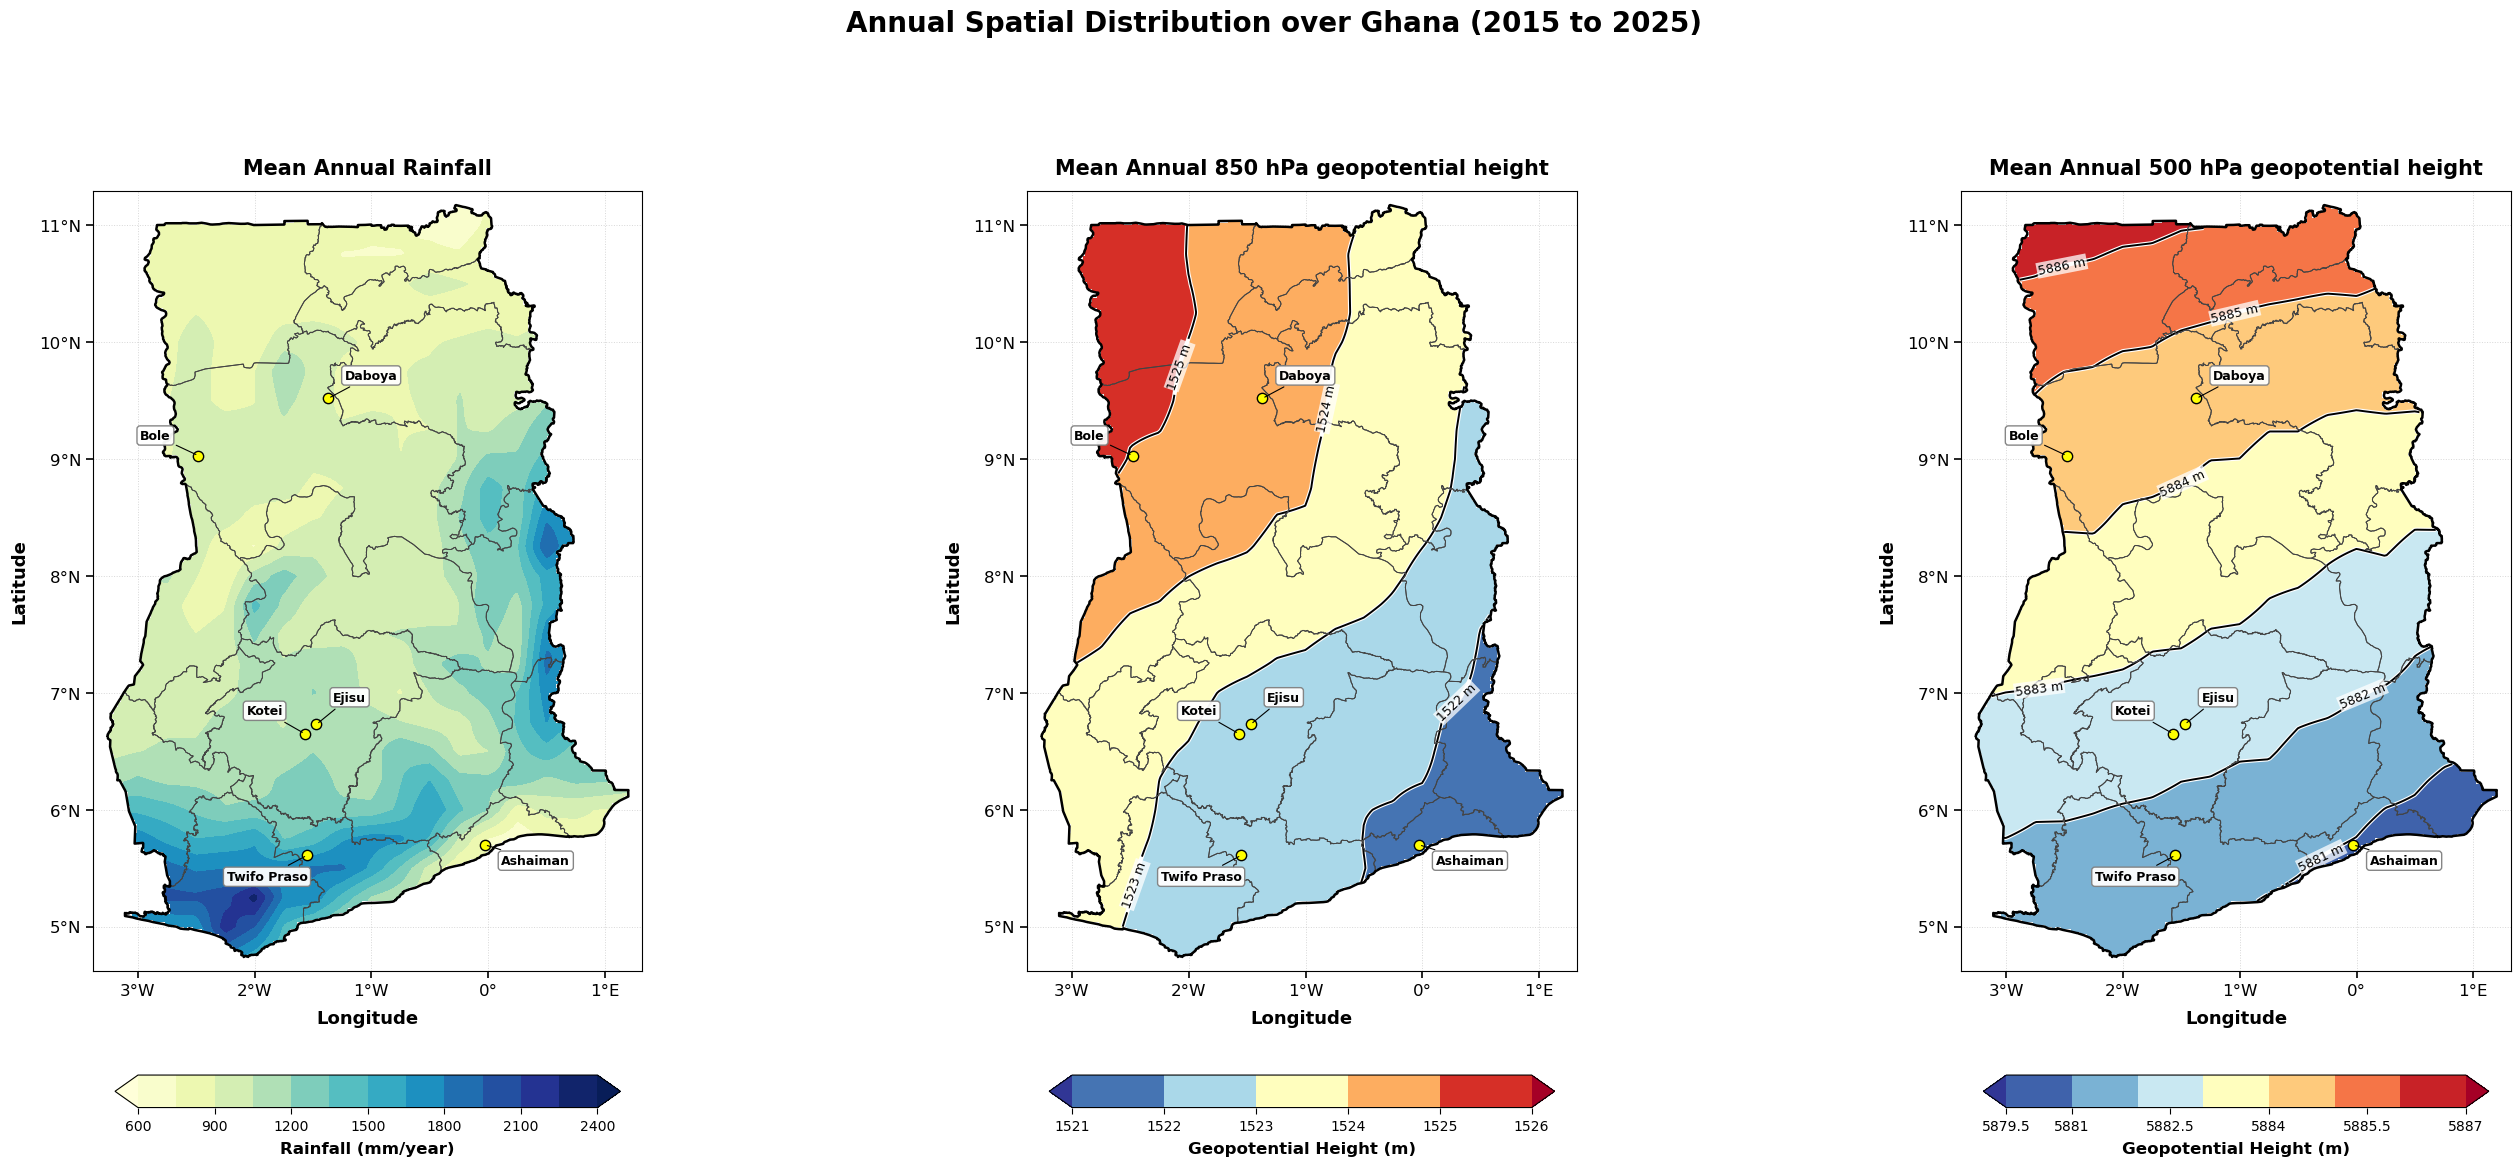

In [17]:
# =============================================================================
# 15. FIGURE 01: ANNUAL SPATIAL MAPS (rainfall, 850 hPa, 500 hPa)
# =============================================================================
print("\nFIGURE 01: ANNUAL SPATIAL MAPS")
annual = {"Rainfall": clim_full.sum("month"),
          "Z850": z850.mean("time"), "Z500": z500.mean("time")}

fig, axes = plt.subplots(1, 3, figsize=(28, 13), constrained_layout=False)
fig.subplots_adjust(left=0.035, right=0.985, bottom=0.22, top=0.82, wspace=0.18)
for ax, key in zip(axes, FIELDS):
    cmap = PRECIP_CMAP if key == "Rainfall" else Z_CMAP
    levels = nice_levels([annual[key]], 14 if key == "Rainfall" else 16,
                         integer=(key != "Rainfall"))
    cf = draw_field(ax, annual[key], levels, cmap, key if key != "Rainfall" else None)
    finish_map(ax, "Mean Annual Rainfall" if key == "Rainfall"
               else f"Mean Annual {META[key]['name']}")
    add_map_colourbar(fig, ax, cf, "Rainfall (mm/year)" if key == "Rainfall"
                      else "Geopotential Height (m)")
fig.suptitle(f"Annual Spatial Distribution over Ghana ({START_YEAR} to {END_YEAR})",
             fontsize=20, fontweight="bold", y=0.96)
save(fig, "01_annual_spatial_maps.png")



SEASONAL MAPS: Seasonal Rainfall Total


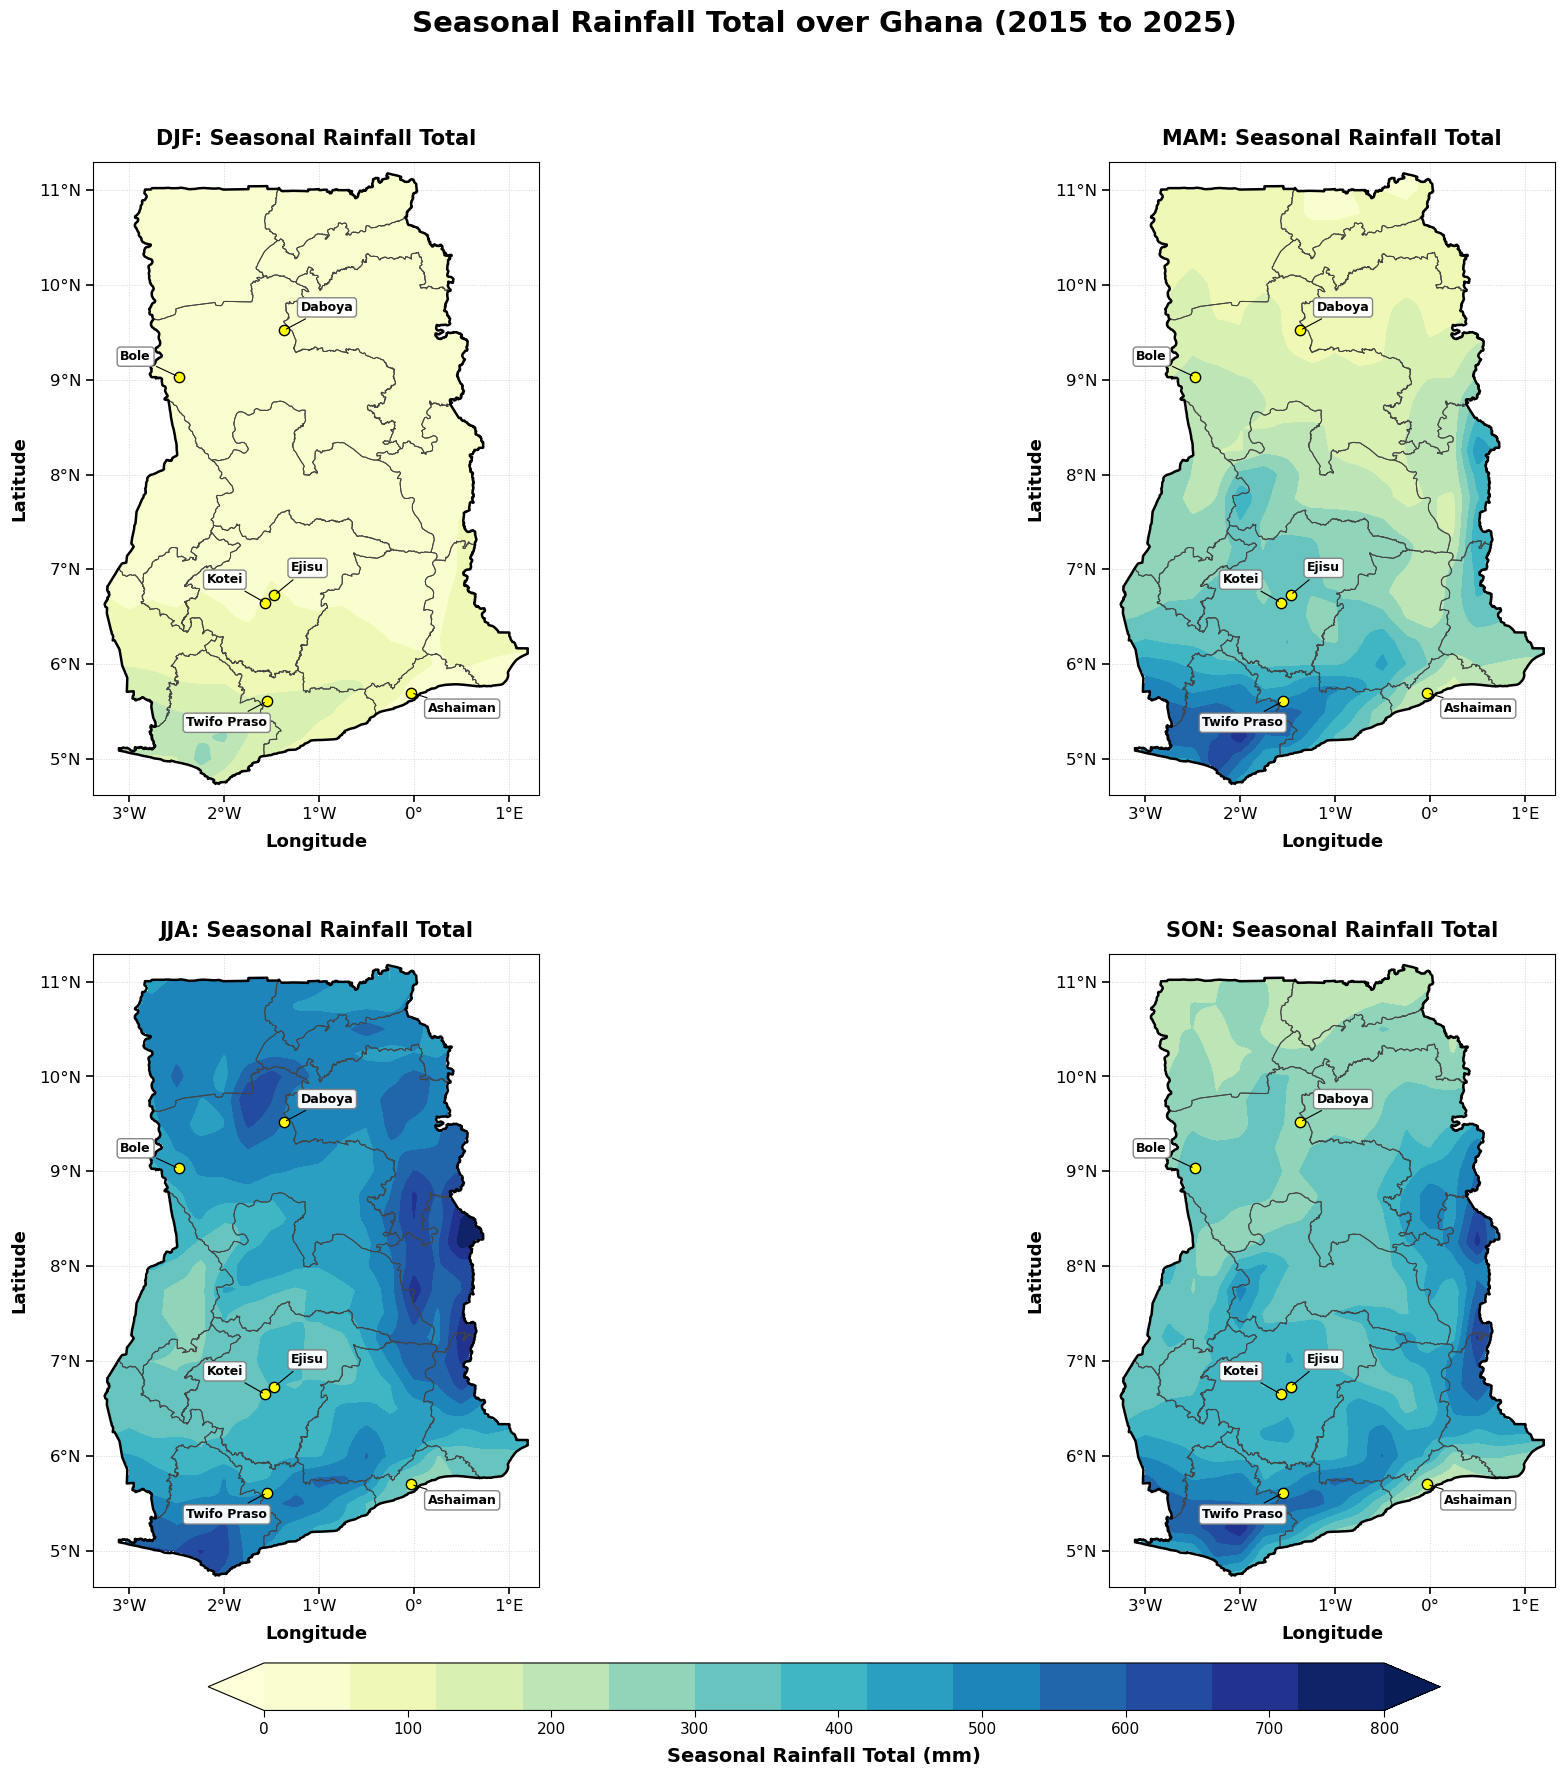


SEASONAL MAPS: 850 hPa Geopotential Height


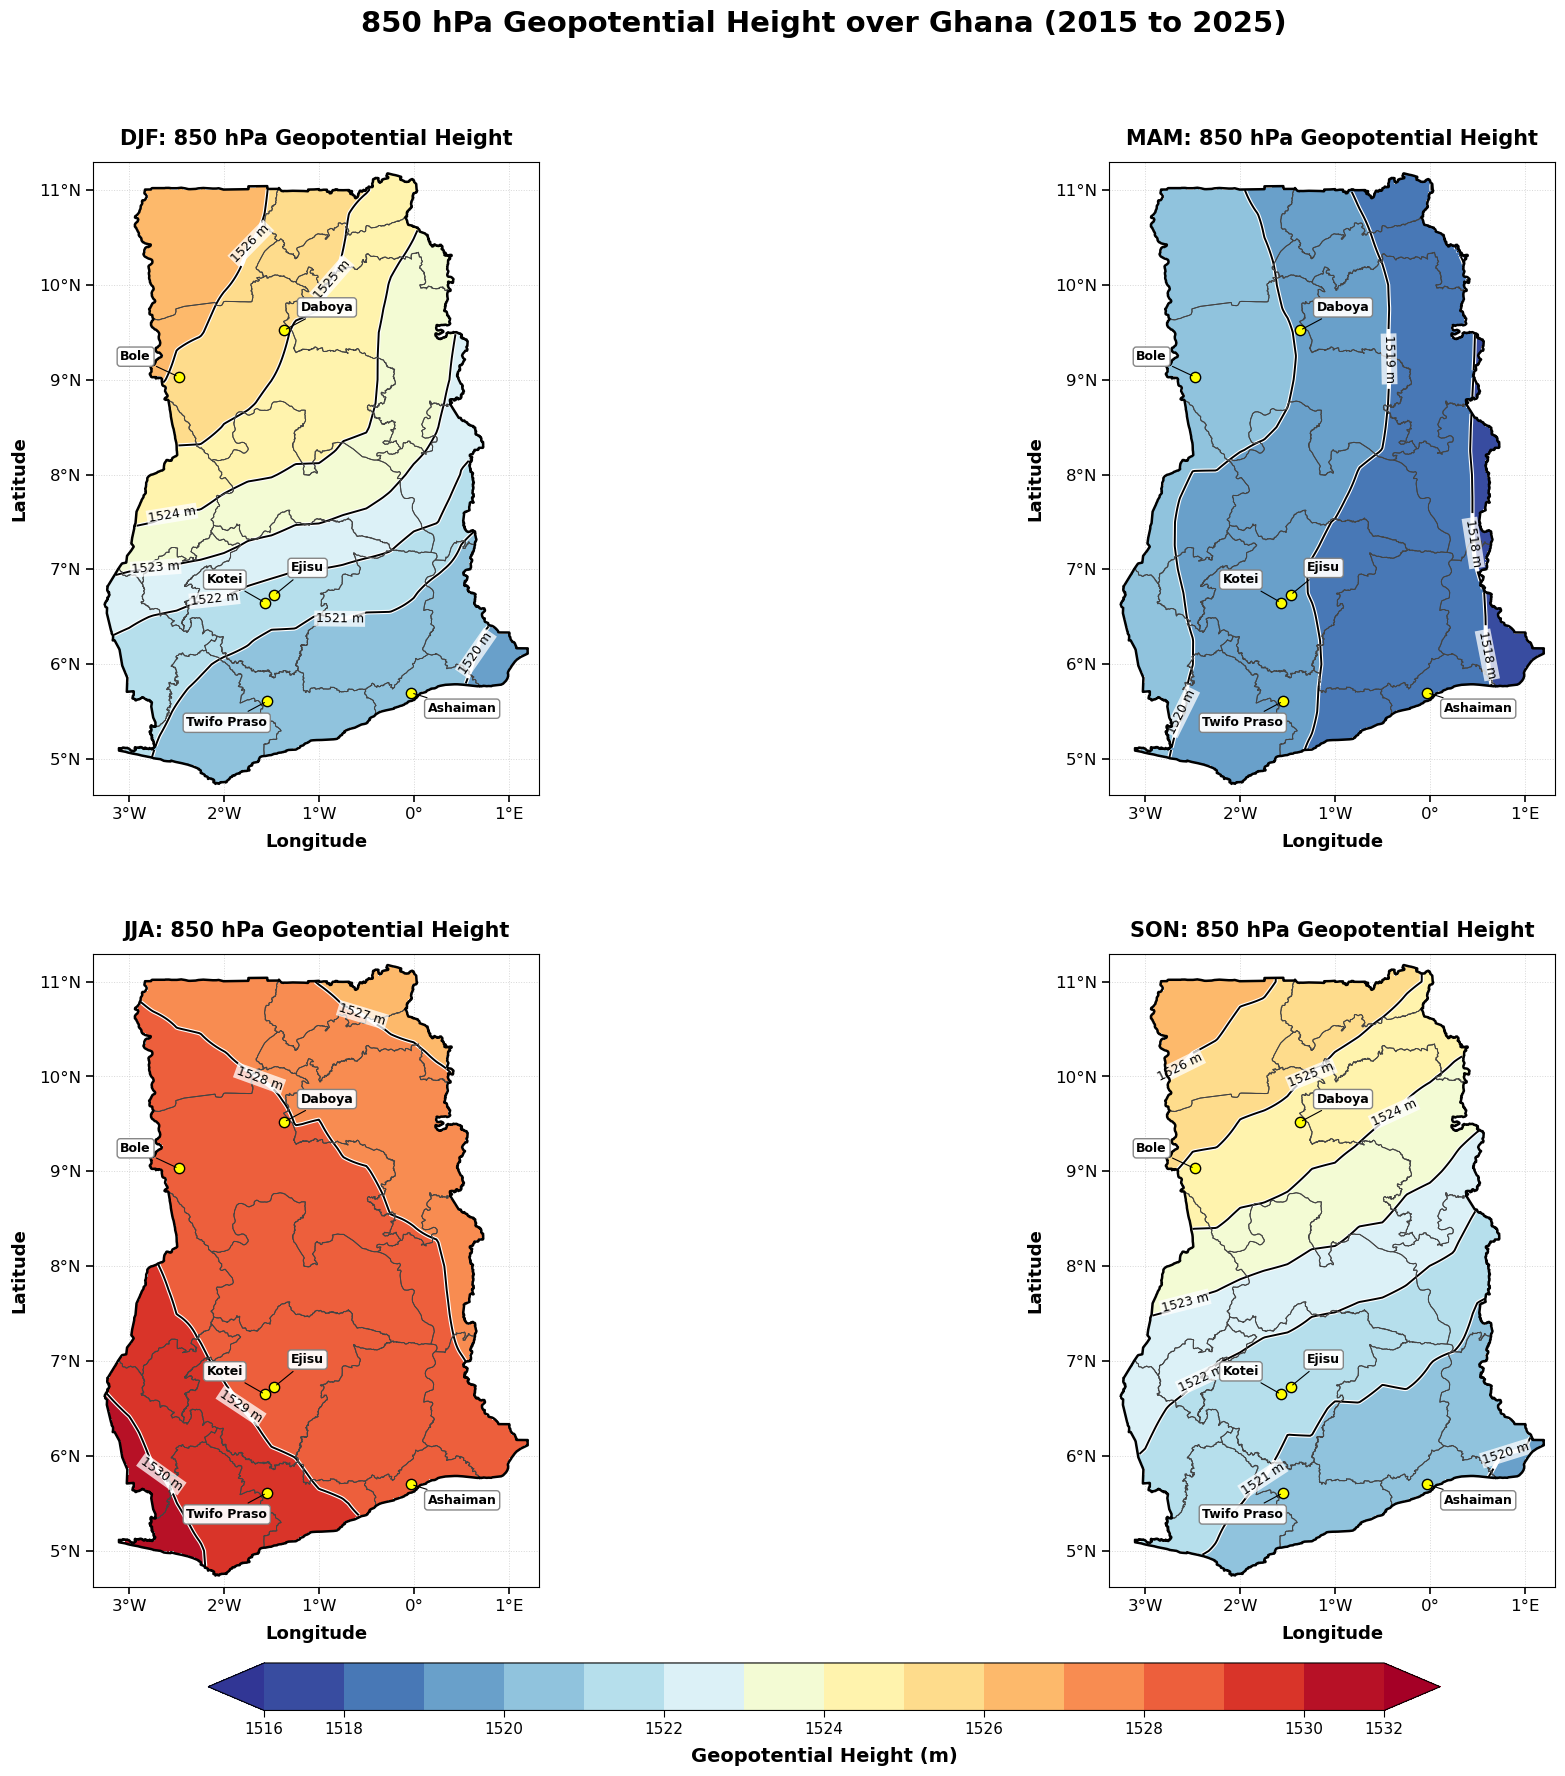


SEASONAL MAPS: 500 hPa Geopotential Height


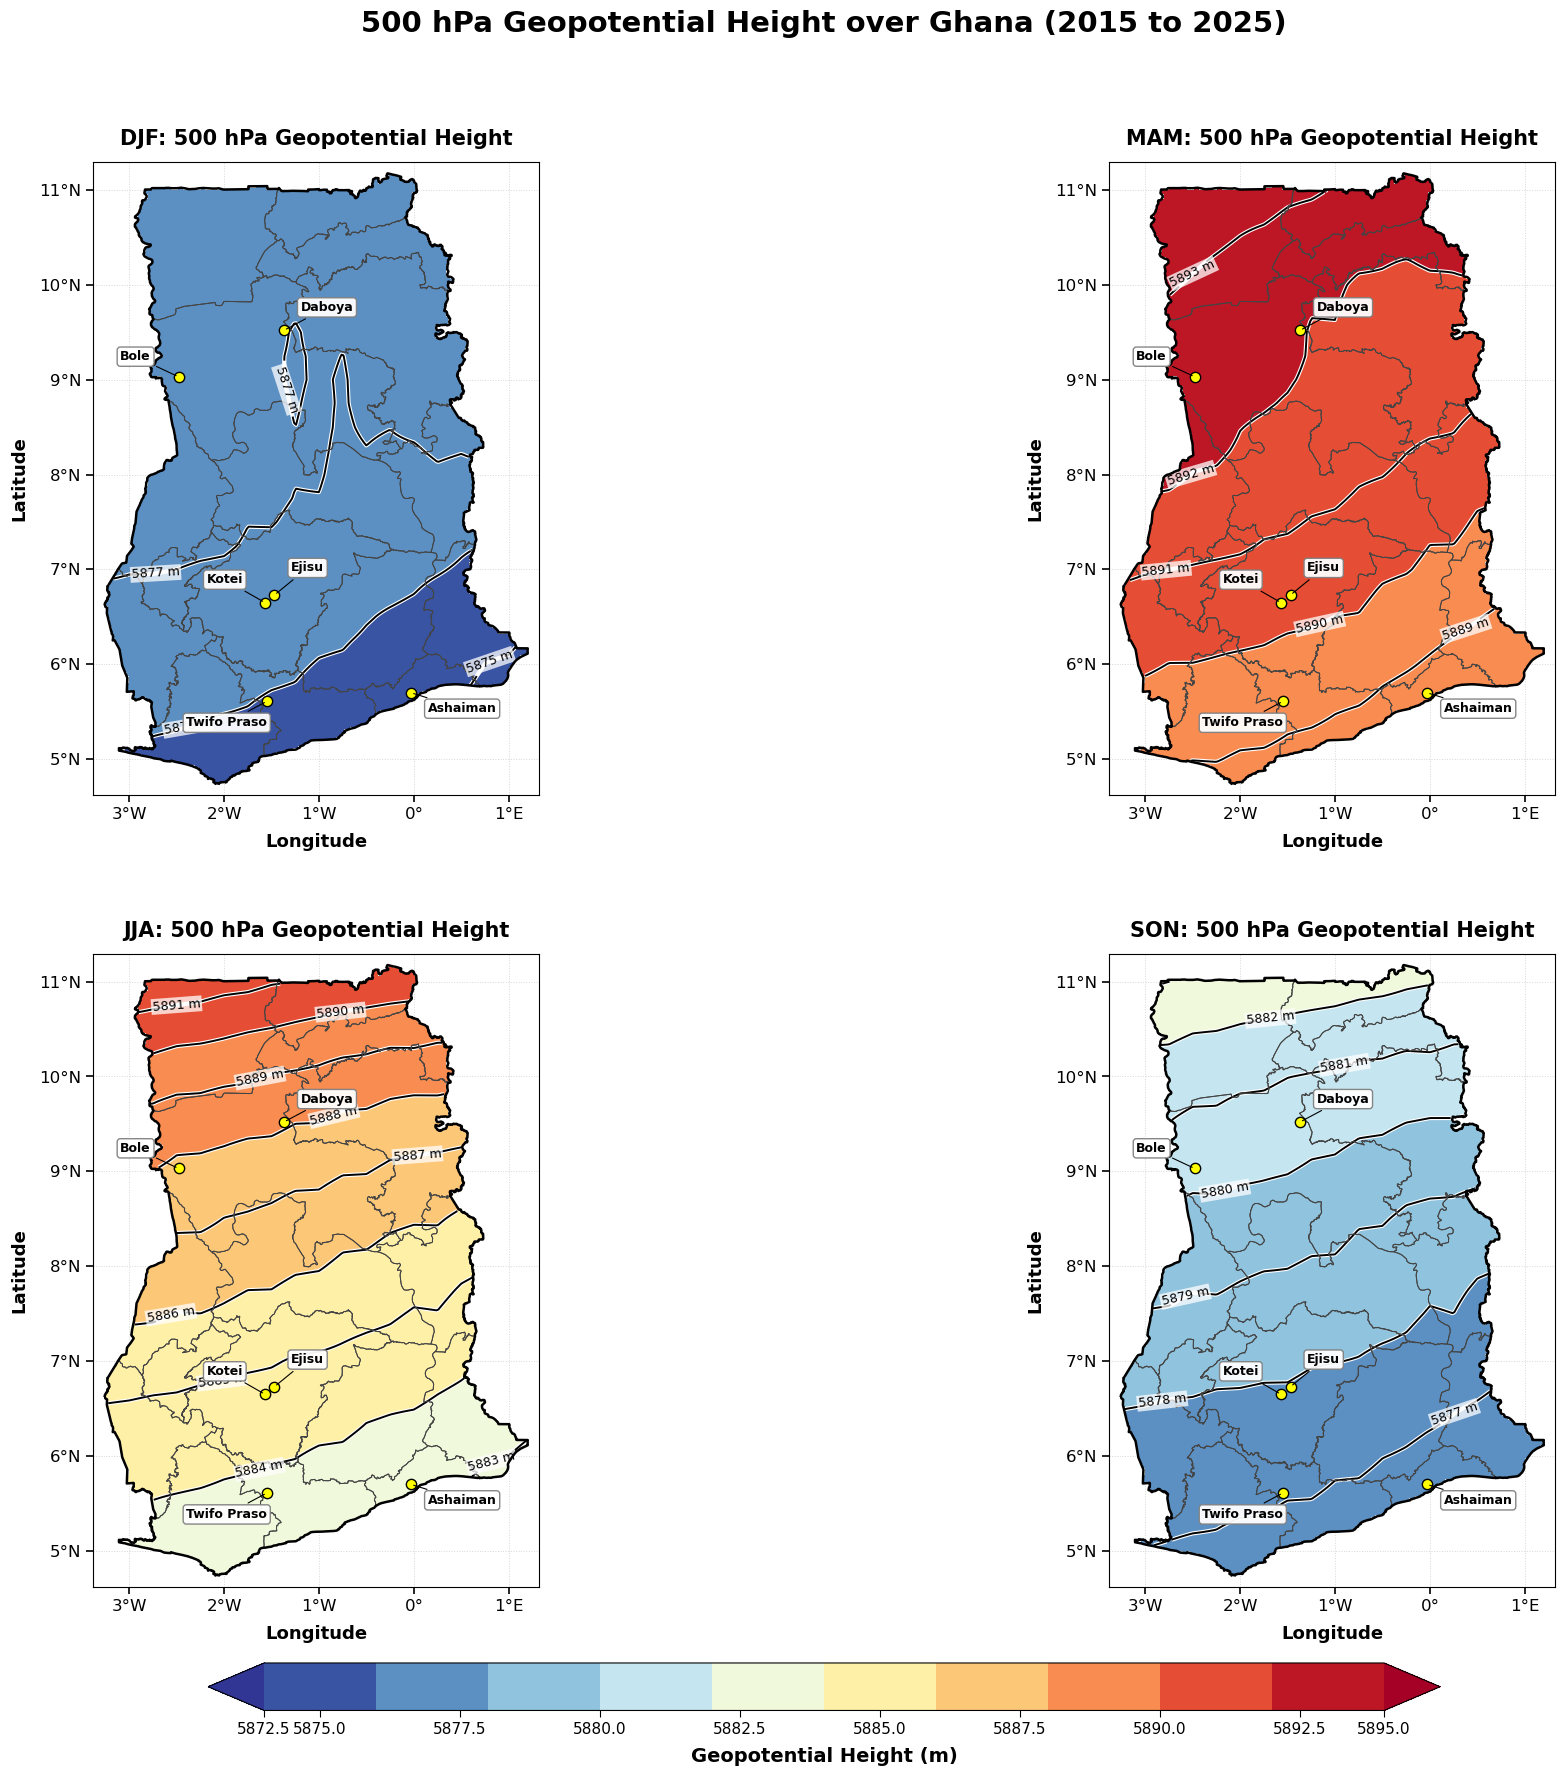

In [18]:
# =============================================================================
# 16. FIGURES 02, 02b, 02c: SEASONAL MAPS (rainfall, 850 hPa, 500 hPa)
# =============================================================================
seasonal_sources = [
    ("Rainfall", seas_rain, "02_seasonal_rainfall_maps.png",
     "Seasonal Rainfall Total", "Seasonal Rainfall Total (mm)"),
    ("Z850", seas_z["Z850"], "02b_seasonal_850hPa_height_maps.png",
     "850 hPa Geopotential Height", "Geopotential Height (m)"),
    ("Z500", seas_z["Z500"], "02c_seasonal_500hPa_height_maps.png",
     "500 hPa Geopotential Height", "Geopotential Height (m)"),
]

for key, source, filename, title, cbar_label in seasonal_sources:
    print(f"\nSEASONAL MAPS: {title}")
    fields = [source.sel(season=s) for s in SEASONS]
    cmap = PRECIP_CMAP if key == "Rainfall" else Z_CMAP
    levels = nice_levels(fields, 14 if key == "Rainfall" else 16,
                         integer=(key != "Rainfall"))

    fig, axes = plt.subplots(2, 2, figsize=(22, 19), constrained_layout=False)
    fig.subplots_adjust(left=0.07, right=0.93, bottom=0.13, top=0.88, wspace=0.16, hspace=0.25)
    for ax, season in zip(axes.ravel(), SEASONS):
        cf = draw_field(ax, source.sel(season=season), levels, cmap,
                        key if key != "Rainfall" else None)
        finish_map(ax, f"{season}: {title}")

    cax = fig.add_axes([0.22, 0.065, 0.56, 0.025])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
    cb.set_label(cbar_label, fontsize=14, fontweight="bold", labelpad=7)
    cb.locator = MaxNLocator(nbins=8)
    cb.update_ticks()
    cb.ax.tick_params(labelsize=11, length=5)
    fig.suptitle(f"{title} over Ghana ({START_YEAR} to {END_YEAR})",
                 fontsize=21, fontweight="bold", y=0.96)
    save(fig, filename)



EXTRACTING DATA AT THE SIX LOCATIONS
  NOTE: Kotei and Ejisu fall in the same data grid cell, so their results are nearly identical (the data are 0.25 degrees).
  NOTE: Ejisu and Kotei fall in the same data grid cell, so their results are nearly identical (the data are 0.25 degrees).

GRID CELLS NEAREST TO EACH SITE
       Site  Site lat  Site lon  Rain grid lat  Rain grid lon  Height grid lat  Height grid lon  Months Shares grid cell with
   Ashaiman      5.70     -0.03           5.75           0.00             5.75             0.00     132                  none
      Kotei      6.65     -1.57           6.75          -1.50             6.75            -1.50     132                 Ejisu
      Ejisu      6.73     -1.47           6.75          -1.50             6.75            -1.50     132                 Kotei
     Daboya      9.52     -1.37           9.50          -1.25             9.50            -1.25     132                  none
       Bole      9.03     -2.48           9.00     

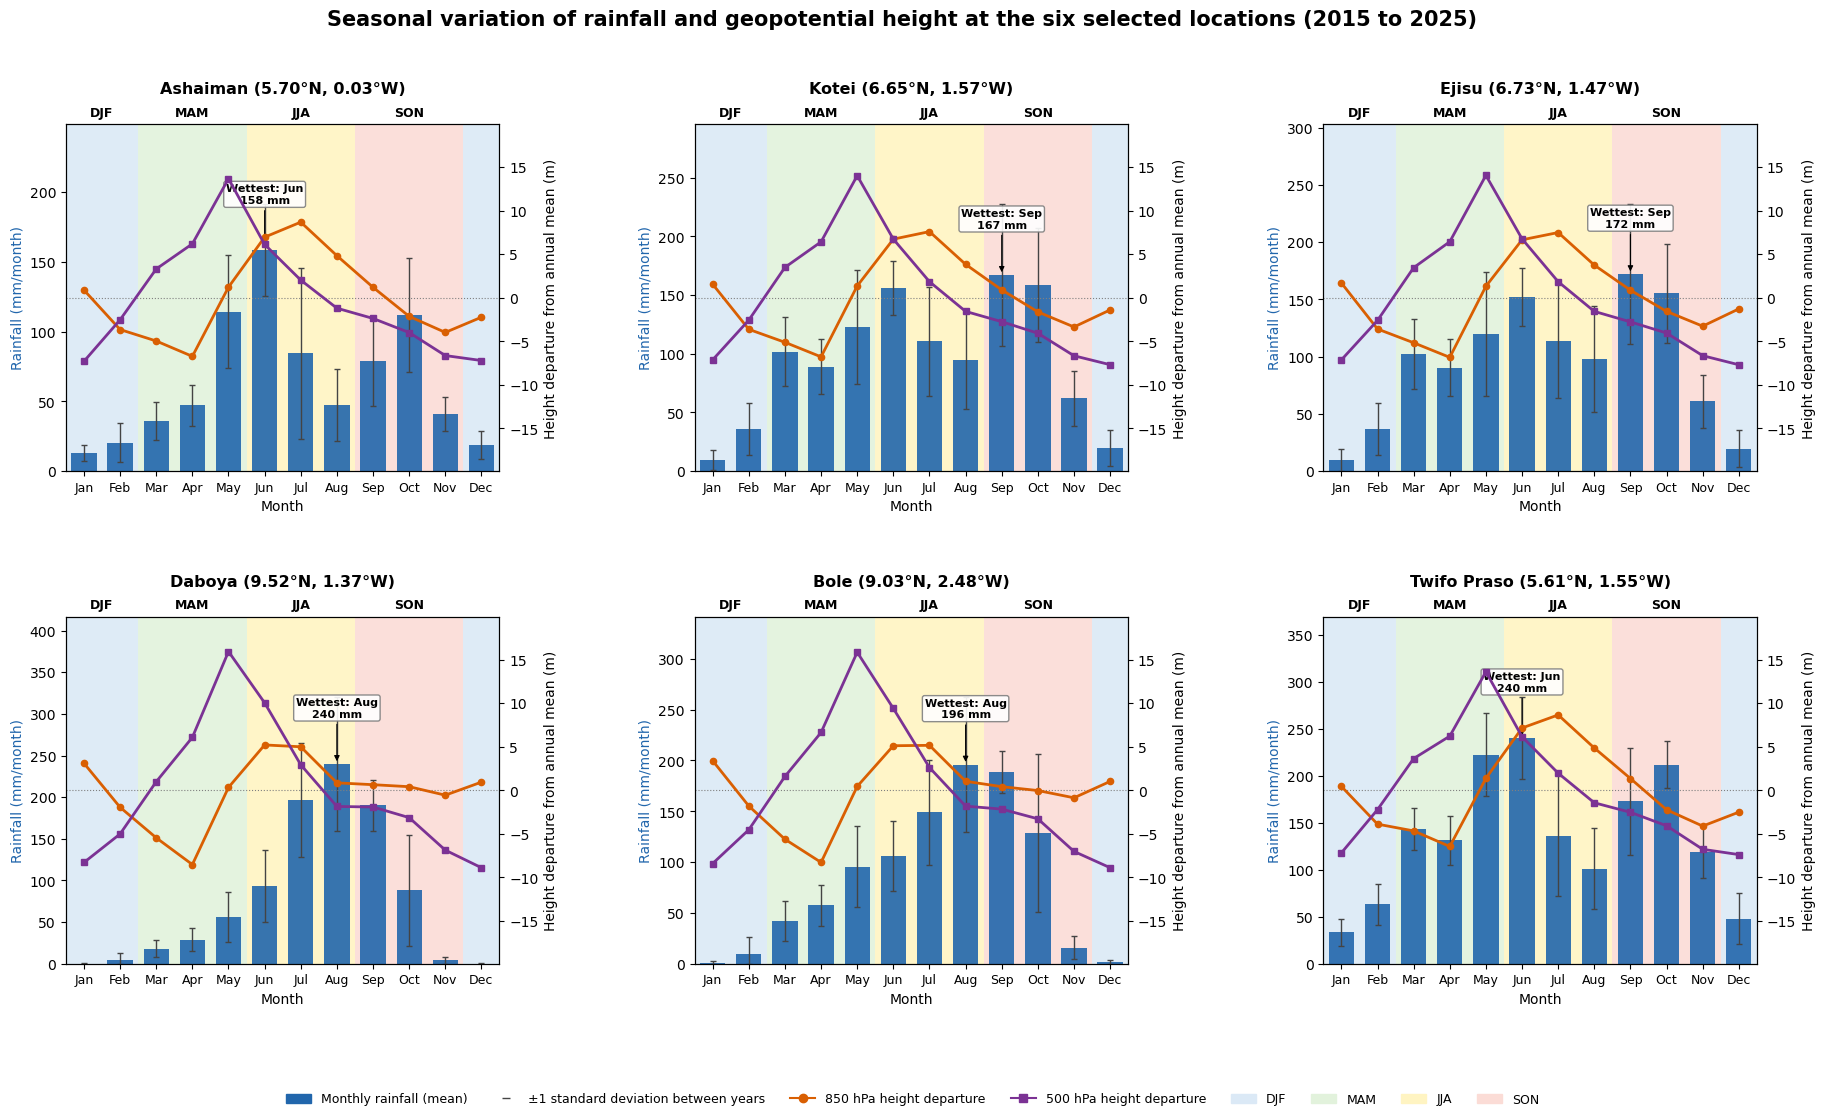

In [19]:
# =============================================================================
# 17. SEASONAL VARIATION AT THE SIX SELECTED LOCATIONS
# =============================================================================
print("\nEXTRACTING DATA AT THE SIX LOCATIONS")


def extract_site(da, la, lo, label):
    """Linear interpolation to the site; nearest grid cell if that gives NaN."""
    v = da.interp(latitude=la, longitude=lo, method="linear")
    if bool(v.isnull().all()):
        v = da.sel(latitude=la, longitude=lo, method="nearest")
        print(f"  NOTE: {label}: interpolation gave NaN, nearest cell used.")
    return pd.Series(np.asarray(v.values, dtype=float).ravel(),
                     index=pd.DatetimeIndex(v.time.values), name=label)


site_ts = {}
grid_rows = []
for name, (la, lo) in SITES.items():
    # rainfall from its own grid; heights from the geopotential grid
    df = pd.concat([extract_site(rain_full, la, lo, "Rainfall"),
                    extract_site(z850, la, lo, "Z850"),
                    extract_site(z500, la, lo, "Z500")], axis=1).dropna().sort_index()
    if df.empty:
        raise ValueError(f"No data found for {name} at ({la}, {lo}). "
                         "Check that the site is inside your data domain.")
    site_ts[name] = df
    rn = rain_full.sel(latitude=la, longitude=lo, method="nearest")
    zn = z850.sel(latitude=la, longitude=lo, method="nearest")
    grid_rows.append({"Site": name, "Site lat": la, "Site lon": lo,
                      "Rain grid lat": float(rn.latitude), "Rain grid lon": float(rn.longitude),
                      "Height grid lat": float(zn.latitude), "Height grid lon": float(zn.longitude),
                      "Months": len(df)})
grid_table = pd.DataFrame(grid_rows)
cell_key = list(zip(grid_table["Height grid lat"], grid_table["Height grid lon"]))
grid_table["Shares grid cell with"] = [
    ", ".join(grid_table["Site"][j] for j in range(len(cell_key))
              if j != i and cell_key[j] == cell_key[i]) or "none"
    for i in range(len(cell_key))]
for _, rw in grid_table[grid_table["Shares grid cell with"] != "none"].iterrows():
    print(f"  NOTE: {rw['Site']} and {rw['Shares grid cell with']} fall in the same data grid cell, "
          "so their results are nearly identical (the data are 0.25 degrees).")
print("\nGRID CELLS NEAREST TO EACH SITE")
print(grid_table.round(3).to_string(index=False))
save_csv(grid_table.round(4), "site_grid_cells.csv", index=False)

# ---- 17A. monthly climatology, spread between years, departures -------------
site_clim = {name: df.groupby(df.index.month).mean() for name, df in site_ts.items()}
site_std = {name: df.groupby(df.index.month).std() for name, df in site_ts.items()}
site_dep = {name: sc[["Z850", "Z500"]] - sc[["Z850", "Z500"]].mean()
            for name, sc in site_clim.items()}
save_csv(pd.concat(site_clim, axis=1).round(3), "site_monthly_climatology.csv")

# ---- 17B. four season climatology (rainfall = seasonal total) ---------------
season_start_to_name = {12: "DJF", 3: "MAM", 6: "JJA", 9: "SON"}
seasonal_site_clim = {}
for name, df in site_ts.items():
    sv = df.resample("QS-DEC").agg({"Rainfall": "sum", "Z850": "mean", "Z500": "mean"})
    counts = df.resample("QS-DEC").count()
    sv = sv.loc[(counts == 3).all(axis=1)].copy()          # complete seasons only
    sv["Season"] = [season_start_to_name[d.month] for d in sv.index]
    seasonal_site_clim[name] = (sv.groupby("Season")[["Rainfall", "Z850", "Z500"]]
                                .mean().reindex(SEASONS))

seasonal_table = (pd.concat(seasonal_site_clim, names=["Site", "Season"])
                  .rename_axis(index=["Site", "Season"]).reset_index())
seasonal_table["Rain share (%)"] = (
    100 * seasonal_table["Rainfall"] /
    seasonal_table.groupby("Site")["Rainfall"].transform("sum"))
save_csv(seasonal_table.round(3), "site_four_season_climatology.csv", index=False)


# ---- 17C. summary of each location's rainfall regime ------------------------
def rainfall_regime(values):
    """Approximate number of rainy seasons from the monthly cycle (circular)."""
    v = np.asarray(values, dtype=float)
    spread = v.max() - v.min()
    if spread <= 0:
        return "No clear peak"
    ext = np.concatenate([v[-3:], v, v[:3]])
    peaks, _ = find_peaks(ext, prominence=0.2 * spread)
    n = int(np.sum((peaks >= 3) & (peaks < 15)))
    if n == 1:
        return "One rainy season"
    if n == 2:
        return "Two rainy seasons"
    return f"{n} rainfall peaks" if n > 2 else "No clear peak"


summary_rows = []
for name in SITES:
    rc = site_clim[name]["Rainfall"]
    sr = seasonal_site_clim[name]["Rainfall"]
    summary_rows.append({
        "Location": name,
        "Annual rainfall (mm)": rc.sum(),
        "Wettest month": MONTHS[int(rc.idxmax()) - 1],
        "Peak (mm/month)": rc.max(),
        "Driest month": MONTHS[int(rc.idxmin()) - 1],
        "Minimum (mm/month)": rc.min(),
        "Wettest season": sr.idxmax(),
        "Driest season": sr.idxmin(),
        "Rainfall regime": rainfall_regime(rc.values),
    })
season_summary = pd.DataFrame(summary_rows)
save_csv(season_summary.round(2), "site_seasonal_summary.csv", index=False)

print("\nFOUR SEASON CLIMATOLOGY AT THE SIX LOCATIONS (rainfall = seasonal total, mm)")
print(seasonal_table.round(2).to_string(index=False))
print("\nSEASONAL SUMMARY AT THE SIX LOCATIONS")
print(season_summary.round(1).to_string(index=False))

# ---- 17D. FIGURE 03: seasonal variation, one panel per location --------------
print("\nFIGURE 03: SEASONAL VARIATION AT THE SIX LOCATIONS")
SEASON_BANDS = [(0.5, 2.5, "DJF"), (2.5, 5.5, "MAM"), (5.5, 8.5, "JJA"),
                (8.5, 11.5, "SON"), (11.5, 12.5, "DJF")]
max_dep = max(float(np.nanmax(np.abs(d.values))) for d in site_dep.values())
dep_lim = max(max_dep * 1.25, 0.5)

fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
fig.subplots_adjust(left=0.06, right=0.95, bottom=0.13, top=0.86, wspace=0.45, hspace=0.42)
for ax, name in zip(axes.ravel(), SITES):
    sc, sd, dep = site_clim[name], site_std[name], site_dep[name]
    for a, b, s in SEASON_BANDS:
        ax.axvspan(a, b, color=SEASON_SHADE[s], alpha=0.9, zorder=0, linewidth=0)
    for a, b, s in SEASON_BANDS[:4]:
        ax.text((a + b) / 2, 1.015, s, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, fontweight="bold")

    means = sc["Rainfall"].values
    spread = np.nan_to_num(sd["Rainfall"].values)
    ax.bar(range(1, 13), means, color=RAIN_BAR_COLOUR, alpha=0.9, width=0.7, zorder=2)
    ax.errorbar(range(1, 13), means, yerr=[np.minimum(spread, means), spread],
                fmt="none", ecolor="#444444", elinewidth=1, capsize=2.5, zorder=3)
    ax.set_ylabel("Rainfall (mm/month)", color=RAIN_BAR_COLOUR, fontsize=10)
    ax.set_ylim(0, float(np.nanmax(means + spread)) * 1.30)

    peak = int(np.argmax(means))
    ax.annotate(f"Wettest: {MONTHS[peak]}\n{means[peak]:.0f} mm", xy=(peak + 1, means[peak]),
                xytext=(0, 34), textcoords="offset points", ha="center", fontsize=8,
                fontweight="bold", arrowprops=dict(arrowstyle="-|>", color="black", lw=0.8),
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="gray", alpha=0.9),
                zorder=6, annotation_clip=False)

    ax2 = ax.twinx()
    ax2.axhline(0, color="gray", linewidth=0.8, linestyle=":")
    ax2.plot(range(1, 13), dep["Z850"].values, "-o", color=Z850_LINE, linewidth=2,
             markersize=4.5, zorder=5)
    ax2.plot(range(1, 13), dep["Z500"].values, "-s", color=Z500_LINE, linewidth=2,
             markersize=4.5, zorder=5)
    ax2.set_ylim(-dep_lim, dep_lim)
    ax2.set_ylabel("Height departure from annual mean (m)", fontsize=10)

    la, lo = SITES[name]
    ax.set_title(f"{name} ({la:.2f}\u00b0N, {abs(lo):.2f}\u00b0{'W' if lo < 0 else 'E'})",
                 fontsize=11.5, fontweight="bold", pad=22)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS, fontsize=9)
    ax.set_xlim(0.5, 12.5)
    ax.set_xlabel("Month")

handles = [Patch(color=RAIN_BAR_COLOUR, label="Monthly rainfall (mean)"),
           Line2D([0], [0], color="#444444", marker="_", linestyle="none",
                  label="\u00b11 standard deviation between years"),
           Line2D([0], [0], color=Z850_LINE, marker="o", label="850 hPa height departure"),
           Line2D([0], [0], color=Z500_LINE, marker="s", label="500 hPa height departure")] + \
          [Patch(color=SEASON_SHADE[s], label=s) for s in SEASONS]
fig.legend(handles=handles, loc="lower center", ncol=8, fontsize=9, frameon=False)
fig.suptitle(f"Seasonal variation of rainfall and geopotential height at the six selected "
             f"locations ({START_YEAR} to {END_YEAR})", fontsize=15, fontweight="bold", y=0.96)
save(fig, "03_seasonal_variation_six_locations.png")



CORRELATION BETWEEN MONTHLY RAINFALL AND GEOPOTENTIAL HEIGHT
(raw = with seasonal cycle, anom = seasonal cycle removed)
       Site Level  r_raw  p_raw  r_anom  p_anom   n
   Ashaiman  Z850  0.295  0.001  -0.075   0.394 132
   Ashaiman  Z500  0.255  0.003  -0.128   0.143 132
      Kotei  Z850  0.123  0.161  -0.147   0.092 132
      Kotei  Z500  0.201  0.021  -0.153   0.080 132
      Ejisu  Z850  0.114  0.193  -0.146   0.094 132
      Ejisu  Z500  0.186  0.033  -0.165   0.059 132
     Daboya  Z850  0.178  0.041  -0.177   0.043 132
     Daboya  Z500  0.093  0.289  -0.116   0.186 132
       Bole  Z850  0.127  0.146  -0.109   0.215 132
       Bole  Z500  0.187  0.032  -0.060   0.496 132
Twifo Praso  Z850  0.185  0.033  -0.027   0.756 132
Twifo Praso  Z500  0.367  0.000   0.007   0.938 132
 Ghana mean  Z850  0.246  0.004  -0.167   0.056 132
 Ghana mean  Z500  0.209  0.016  -0.119   0.173 132

FIGURE 04: CORRELATION BAR GRAPH


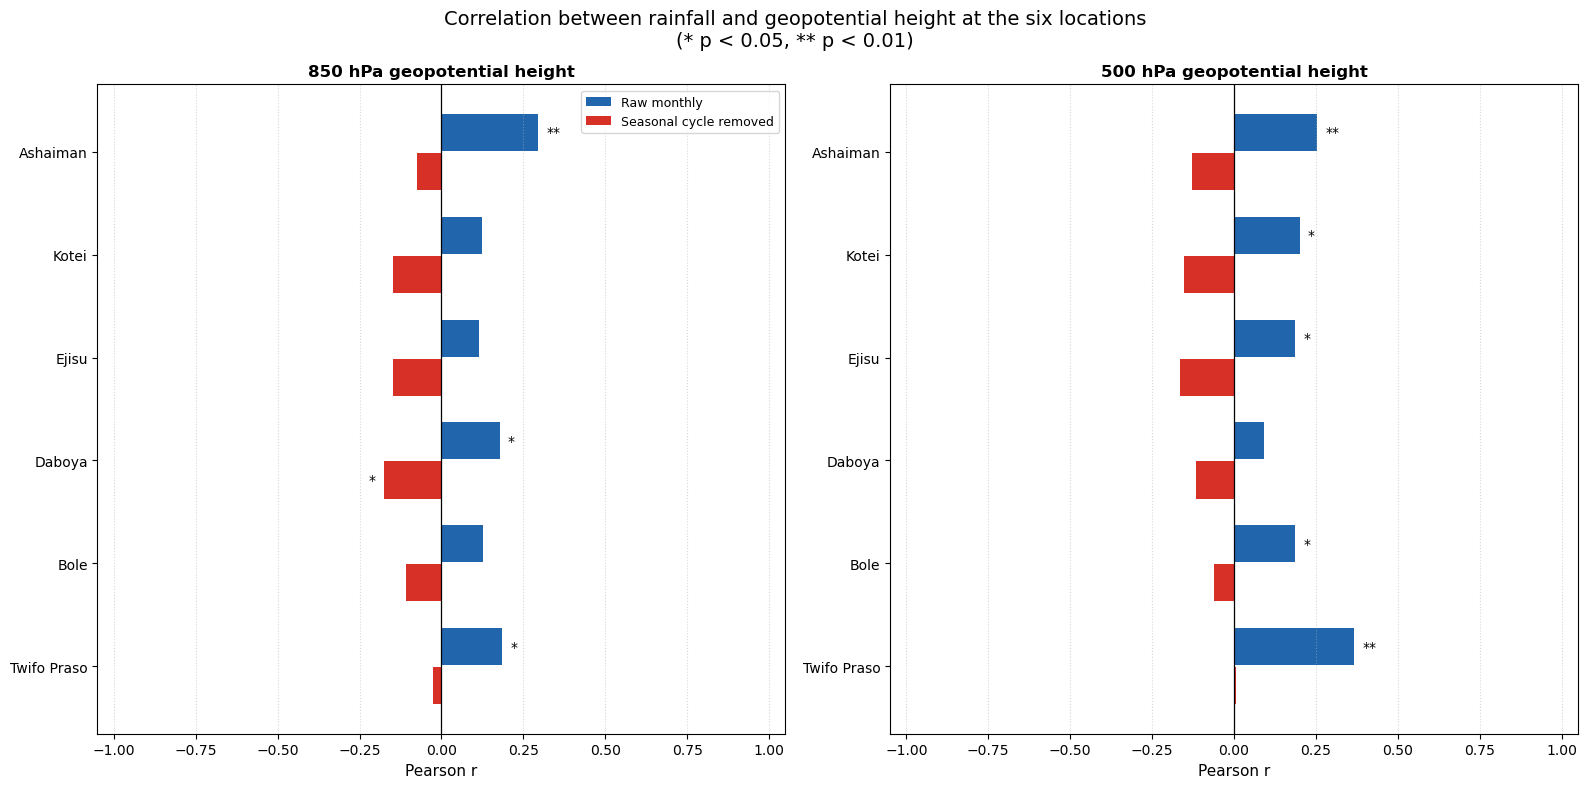

In [20]:
# =============================================================================
# 18. CORRELATION AT THE SIX LOCATIONS (FIGURE 04 AND TABLE T01)
# =============================================================================
def safe_pearson(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    n = len(x)
    if n < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan, np.nan, n
    result = stats.pearsonr(x, y)
    return result[0], result[1], n


def star(p):
    if not np.isfinite(p):
        return ""
    return "**" if p < 0.01 else "*" if p < 0.05 else ""


SITE_ORDER = list(SITES) + ["Ghana mean"]

rows = []
for name, df in site_ts.items():
    an = df.groupby(df.index.month).transform(lambda x: x - x.mean())   # remove seasonal cycle
    for level in ("Z850", "Z500"):
        r_raw, p_raw, _ = safe_pearson(df["Rainfall"], df[level])
        r_anom, p_anom, n_anom = safe_pearson(an["Rainfall"], an[level])
        rows.append({"Site": name, "Level": level, "r_raw": r_raw, "p_raw": p_raw,
                     "r_anom": r_anom, "p_anom": p_anom, "n": n_anom})

# Ghana mean series (area average over Ghana) as an extra row
g_an = g_ts.groupby(g_ts.index.month).transform(lambda x: x - x.mean())
for level in ("Z850", "Z500"):
    r_raw, p_raw, _ = safe_pearson(g_ts["Rainfall"], g_ts[level])
    r_anom, p_anom, n_anom = safe_pearson(g_an["Rainfall"], g_an[level])
    rows.append({"Site": "Ghana mean", "Level": level, "r_raw": r_raw, "p_raw": p_raw,
                 "r_anom": r_anom, "p_anom": p_anom, "n": n_anom})

corr = pd.DataFrame(rows)
save_csv(corr.round(4), "site_correlations.csv", index=False)
print("\n" + "=" * 70)
print("CORRELATION BETWEEN MONTHLY RAINFALL AND GEOPOTENTIAL HEIGHT")
print("(raw = with seasonal cycle, anom = seasonal cycle removed)")
print("=" * 70)
print(corr.round(3).to_string(index=False))

# ---- FIGURE 04: correlation bar graph ---------------------------------------
print("\nFIGURE 04: CORRELATION BAR GRAPH")
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)
ypos_sites = np.arange(len(SITES))
for ax, level in zip(axes, ("Z850", "Z500")):
    d = corr[corr.Level == level].set_index("Site").loc[list(SITES)]
    ax.barh(ypos_sites - 0.19, d["r_raw"], 0.36, color="#2166ac", label="Raw monthly")
    ax.barh(ypos_sites + 0.19, d["r_anom"], 0.36, color="#d73027",
            label="Seasonal cycle removed")
    for i, (_, rw) in enumerate(d.iterrows()):
        for value, pvalue, yy in [(rw["r_raw"], rw["p_raw"], i - 0.19),
                                  (rw["r_anom"], rw["p_anom"], i + 0.19)]:
            if np.isfinite(value):
                ax.text(value + (0.025 if value >= 0 else -0.025), yy, star(pvalue),
                        va="center", ha="left" if value >= 0 else "right", fontsize=10)
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_yticks(ypos_sites)
    ax.set_yticklabels(list(SITES), fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(-1.05, 1.05)
    ax.set_xlabel("Pearson r", fontsize=11)
    ax.set_title(META[level]["name"], fontsize=12, fontweight="bold")
    ax.grid(axis="x", linestyle=":", alpha=0.5)
axes[0].legend(fontsize=9)
fig.suptitle("Correlation between rainfall and geopotential height at the six locations\n"
             "(* p < 0.05, ** p < 0.01)", fontsize=14)
fig.tight_layout()
save(fig, "04_correlation_bars.png")



STANDARDISED ANOMALY INDEX (SAI): GHANA MEAN
SAI = (value - mean) / standard deviation.  > +1 above normal, < -1 below normal.
Monthly SAI uses the mean and standard deviation of the same calendar month.

Monthly SAI: Rainfall (rows = year, columns = month):
       Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
Year                                                                        
2015 -0.08  1.39  0.62 -1.18 -0.41 -1.07 -0.48 -0.15 -0.75 -0.01  0.48 -0.77
2016 -0.41 -0.42  1.72  0.57  1.12  0.56  0.19  0.15 -0.04 -0.13 -0.23  0.81
2017  0.40 -0.23 -1.12  0.75  0.47  0.71  0.23  0.15 -0.22 -0.77  0.34  0.32
2018 -0.50  1.81  0.26  0.56  0.80  0.25  0.86  1.25  0.60 -0.13  0.21 -0.35
2019  2.29  0.38  0.19  1.00  0.38 -0.40  0.62 -0.50  0.52  2.28  1.46 -0.07
2020 -0.33 -0.86  0.79 -0.08 -0.07 -0.77  0.37 -1.15  0.19  0.02 -0.70  0.36
2021  0.01 -0.47 -0.32 -1.20 -1.28  0.06 -0.20  0.93  0.33 -0.71  0.04 -0.65
2022 -0.52 -0.40 -0.48  0.38  0.10  0.37 -0.54 

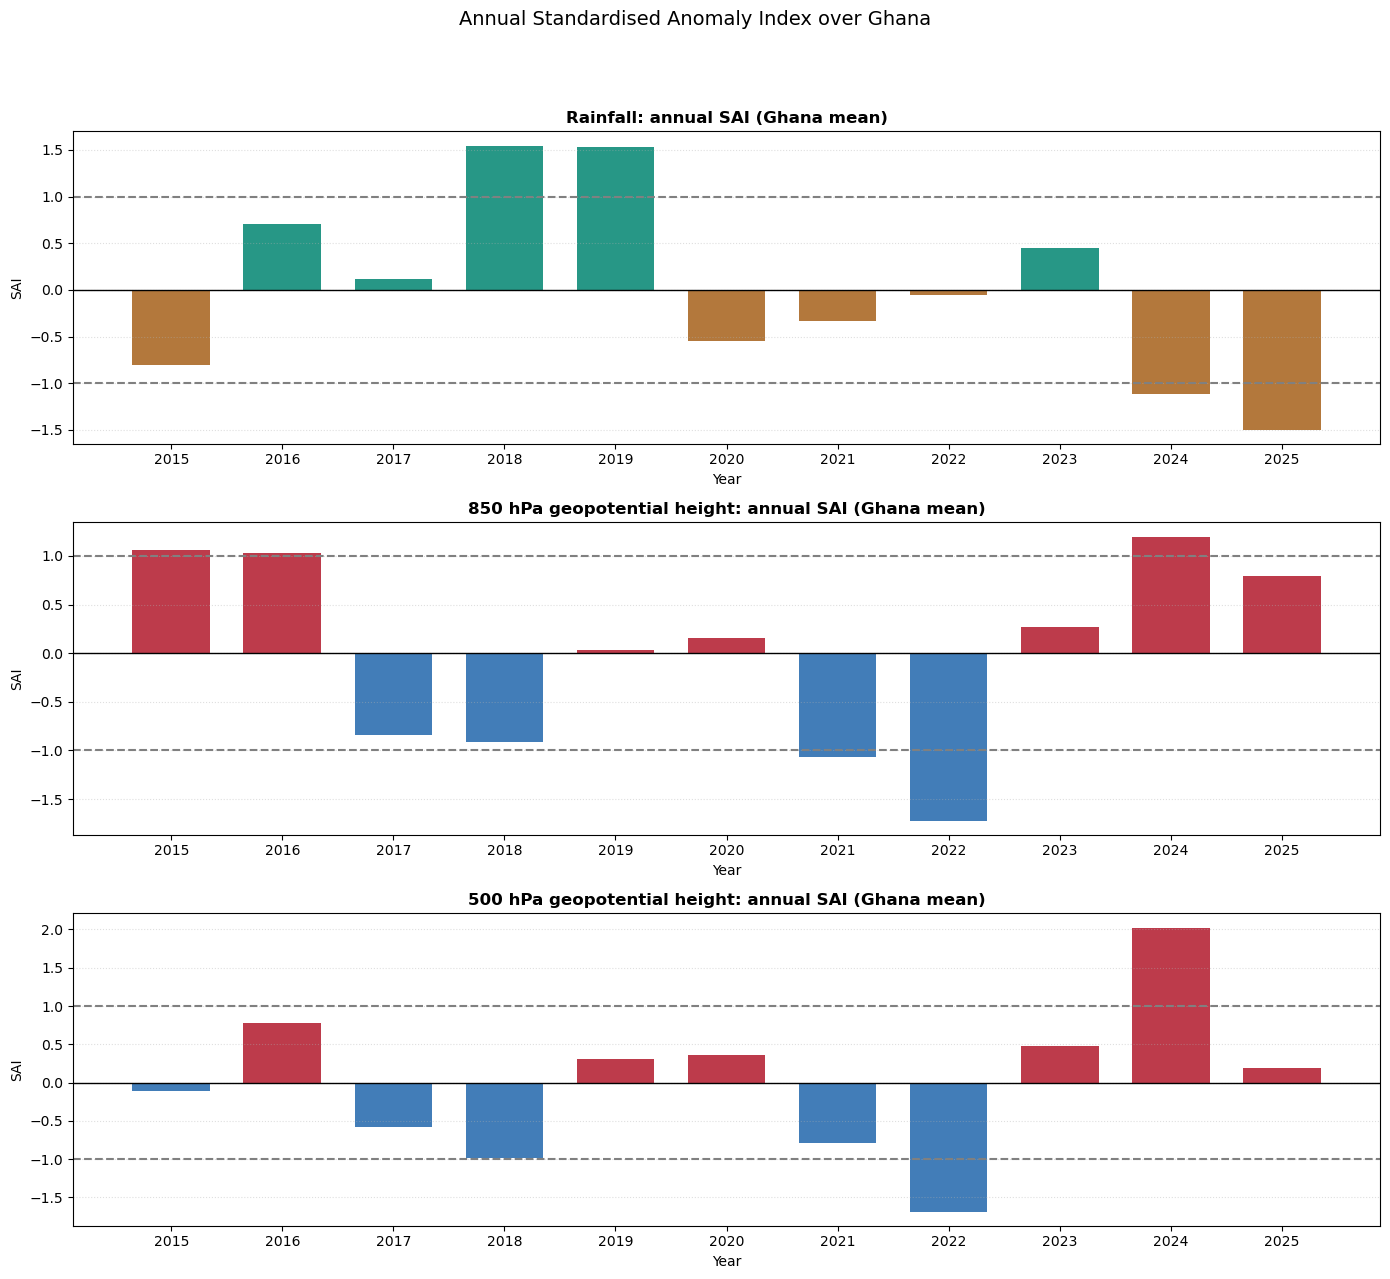


FIGURE 05b: MONTHLY SAI BAR GRAPH


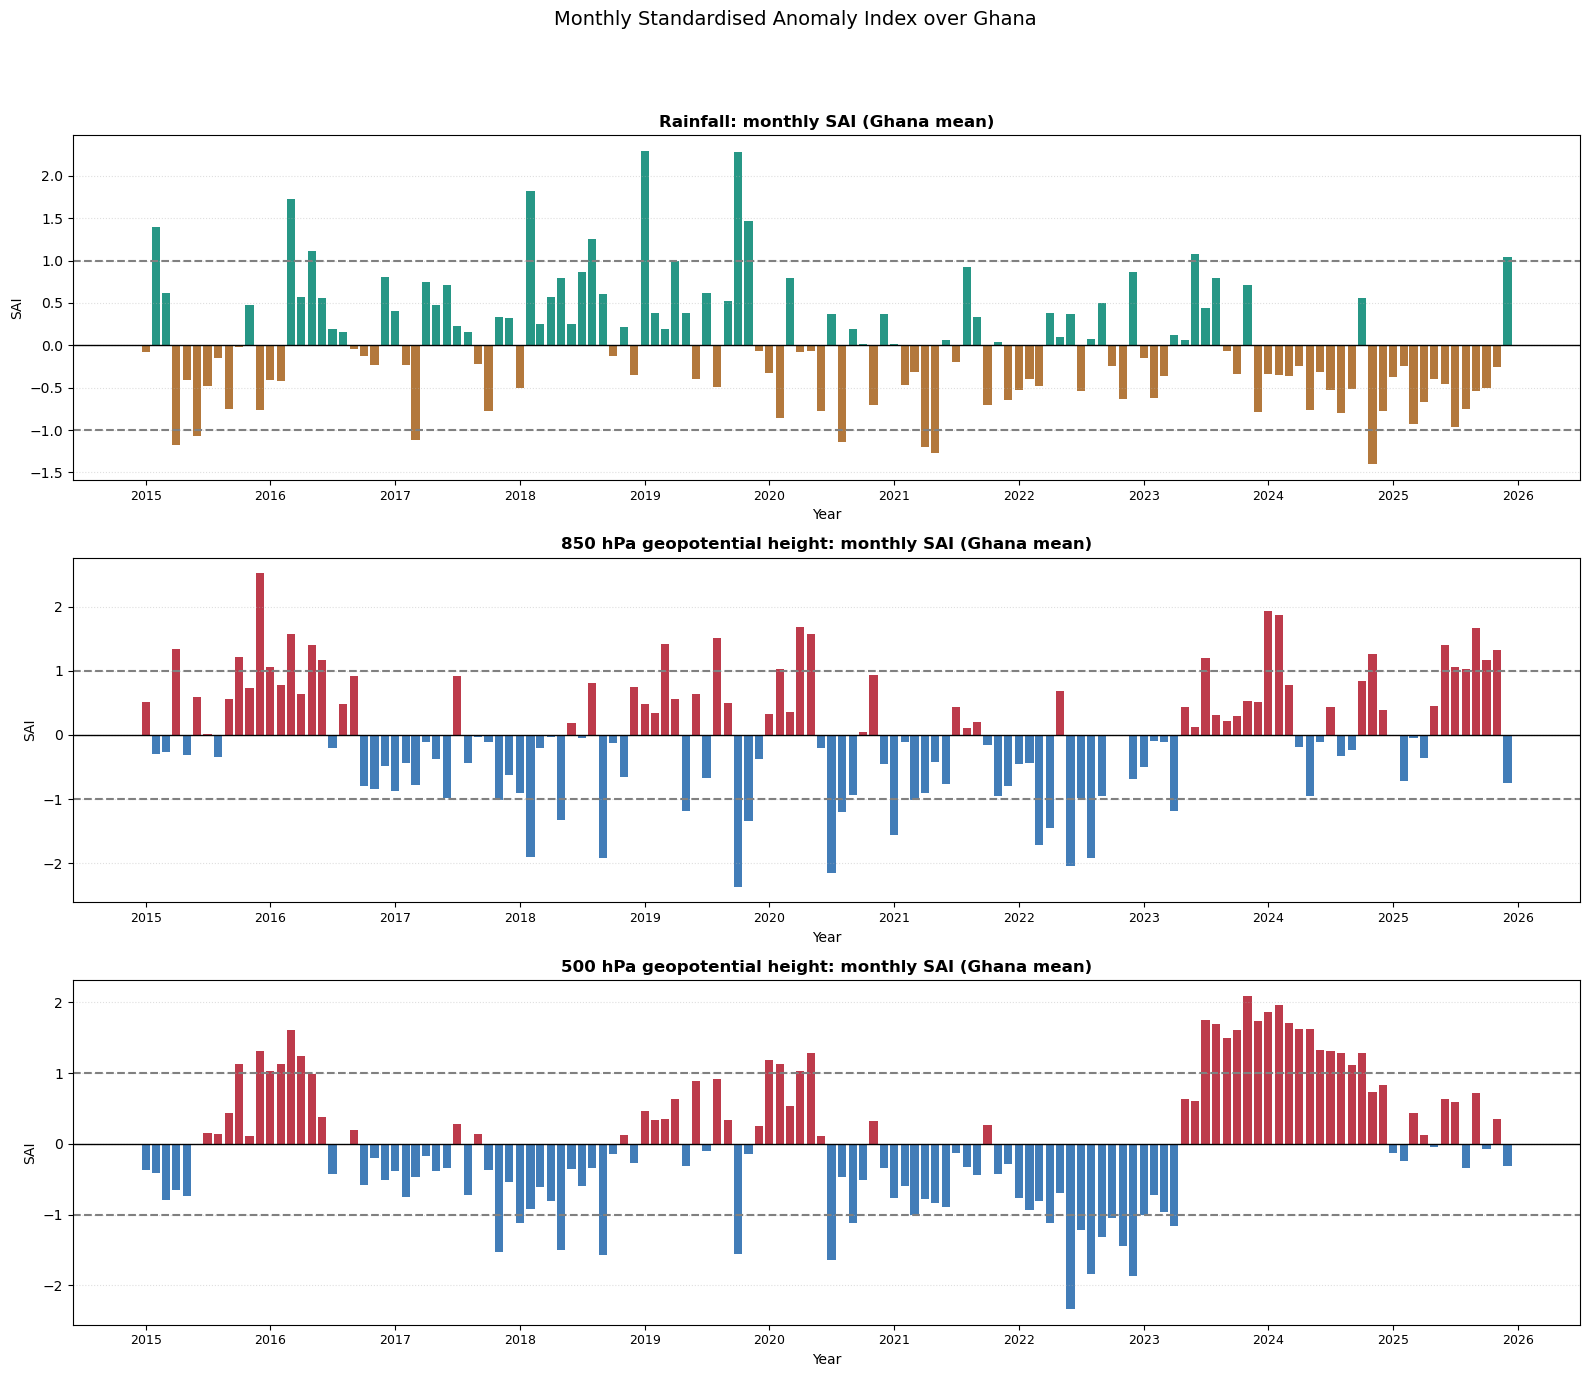

In [21]:
# =============================================================================
# 19. SAI: PRINTED TABLES AND FIGURES 05 / 05b
# =============================================================================
save_csv(g_sai.round(3), "SAI_monthly_Ghana.csv")
save_csv(ann_sai.round(3), "SAI_annual_Ghana.csv")


def sai_year_month(key):
    fr = pd.DataFrame({"Year": g_sai.index.year, "Month": g_sai.index.month, "SAI": g_sai[key].values})
    pv = fr.pivot_table(index="Year", columns="Month", values="SAI")
    pv.columns = MONTHS
    return pv


print("\n" + "=" * 70)
print("STANDARDISED ANOMALY INDEX (SAI): GHANA MEAN")
print("SAI = (value - mean) / standard deviation.  > +1 above normal, < -1 below normal.")
print("Monthly SAI uses the mean and standard deviation of the same calendar month.")
print("=" * 70)
for key in FIELDS:
    print(f"\nMonthly SAI: {META[key]['name']} (rows = year, columns = month):")
    print(sai_year_month(key).round(2).to_string())

print("\nAnnual SAI (Ghana mean; rainfall = annual total, heights = annual mean):")
print(ann_sai.round(2).to_string())

print("\nYEARS WITH ANNUAL SAI >= +1 OR <= -1 (Ghana mean):")
for key in FIELDS:
    hi = [str(yr) for yr, v in ann_sai[key].items() if v >= 1]
    lo = [str(yr) for yr, v in ann_sai[key].items() if v <= -1]
    print(f"  {META[key]['name']}: above normal = {', '.join(hi) or 'none'} | "
          f"below normal = {', '.join(lo) or 'none'}")

print("\nFIGURE 05: ANNUAL SAI BARS")
fig, axes = plt.subplots(3, 1, figsize=(14, 13))
for ax, key in zip(axes, FIELDS):
    s = ann_sai[key]
    positive, negative = BAR_COLOURS[key]
    ax.bar(s.index, s.values, width=0.7, color=np.where(s.values >= 0, positive, negative), alpha=0.85)
    ax.axhline(0, color="black", linewidth=1)
    ax.axhline(1, color="gray", linestyle="--")
    ax.axhline(-1, color="gray", linestyle="--")
    ax.set_xticks(s.index)
    ax.set_xlabel("Year")
    ax.set_ylabel("SAI")
    ax.set_title(f"{META[key]['name']}: annual SAI (Ghana mean)", fontweight="bold")
    ax.grid(axis="y", linestyle=":", alpha=0.4)
fig.suptitle("Annual Standardised Anomaly Index over Ghana", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save(fig, "05_SAI_annual_bars.png")

# ---- FIGURE 05b: monthly SAI bar graph (optional) ---------------------------
if INCLUDE_MONTHLY_SAI_BARS:
    print("\nFIGURE 05b: MONTHLY SAI BAR GRAPH")
    fig, axes = plt.subplots(3, 1, figsize=(16, 14))
    for ax, key in zip(axes, FIELDS):
        sm = g_sai[key]
        positive, negative = BAR_COLOURS[key]
        ax.bar(sm.index, sm.values, width=24,
               color=np.where(sm.values >= 0, positive, negative), alpha=0.85)
        ax.axhline(0, color="black", linewidth=1)
        ax.axhline(1, color="gray", linestyle="--")
        ax.axhline(-1, color="gray", linestyle="--")
        ax.set_ylabel("SAI", fontsize=10)
        ax.set_title(f"{META[key]['name']}: monthly SAI (Ghana mean)", fontweight="bold")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.tick_params(axis="x", labelsize=9)
        ax.set_xlabel("Year")
        ax.grid(axis="y", linestyle=":", alpha=0.4)
    fig.suptitle("Monthly Standardised Anomaly Index over Ghana", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    save(fig, "05b_SAI_monthly_bars.png")



FIGURE 06: CLIMATOLOGICAL HOVMOLLER DIAGRAMS


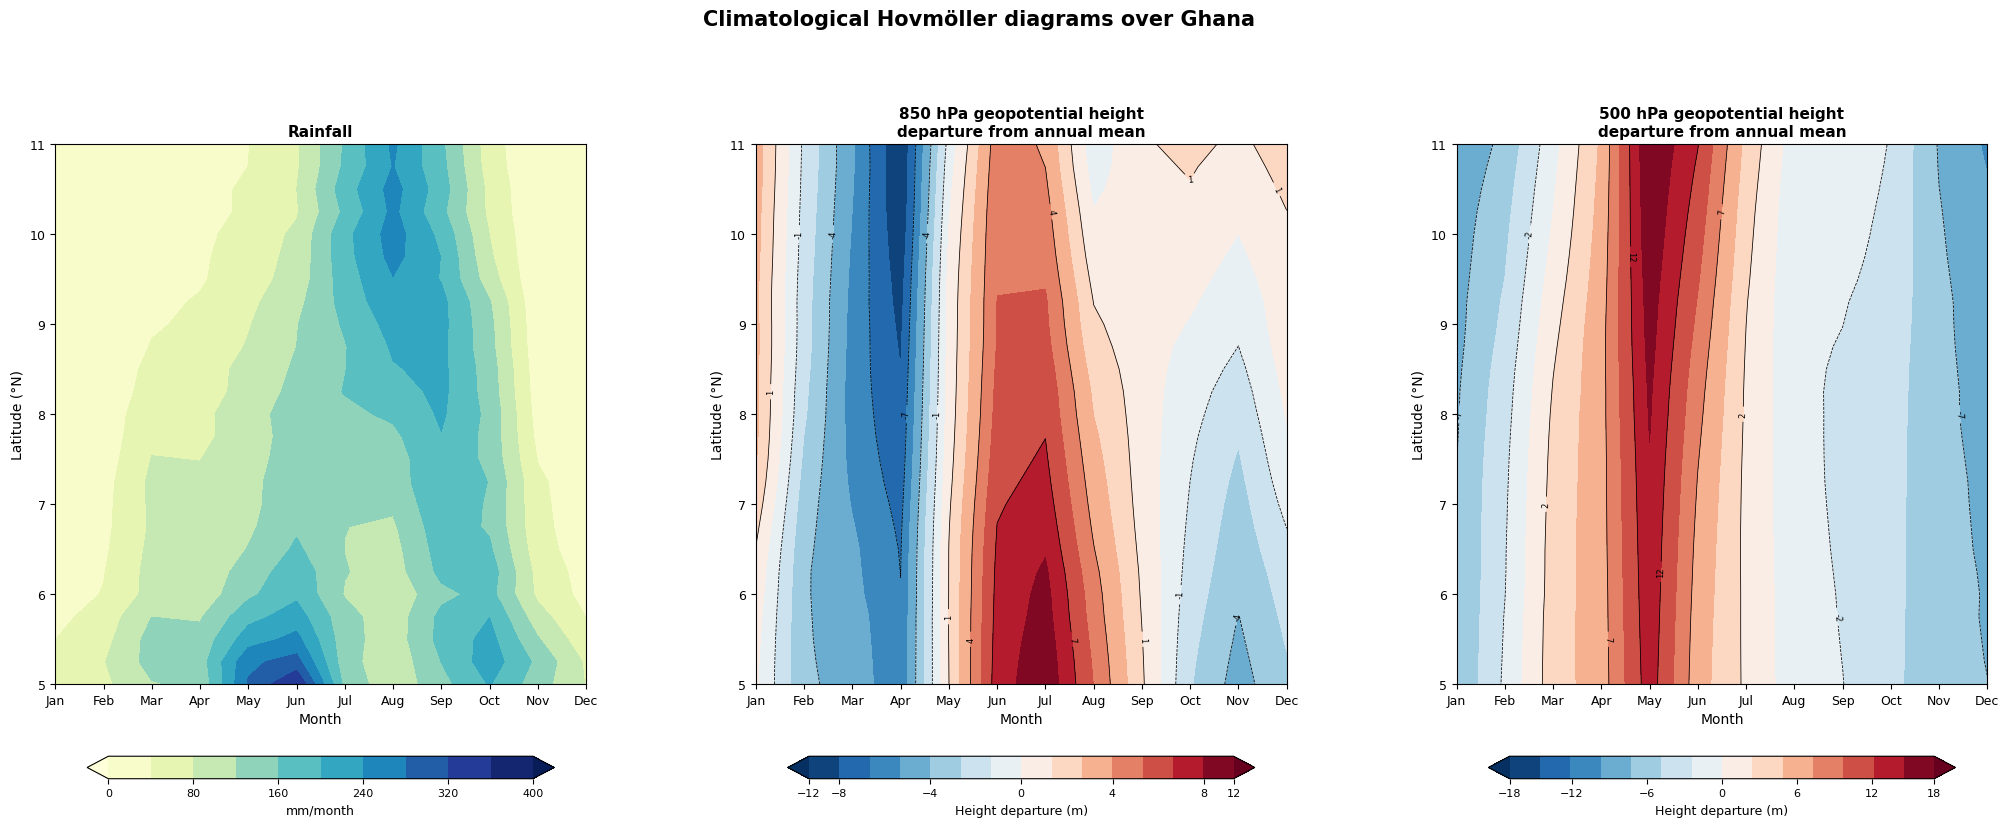

In [22]:
# =============================================================================
# 20. FIGURE 06: CLIMATOLOGICAL HOVMOLLER DIAGRAMS
# =============================================================================
def prepare_hovmoller(da):
    h = da.where(mask).mean("longitude", skipna=True)       # average across longitude
    return h.dropna(dim="latitude", how="all")              # drop rows with no Ghana data


print("\nFIGURE 06: CLIMATOLOGICAL HOVMOLLER DIAGRAMS")
fig, axes = plt.subplots(1, 3, figsize=(21, 9), sharey=False)
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.23, top=0.83, wspace=0.32)
for ax, key in zip(axes, FIELDS):
    h = prepare_hovmoller(clim[key])
    if key == "Rainfall":
        levels = MaxNLocator(12).tick_values(np.nanmin(h.values), np.nanmax(h.values))
        cmap, label, title = PRECIP_CMAP, "mm/month", "Rainfall"
    else:
        h = h - h.mean("month")
        m = float(np.nanmax(np.abs(h.values)))
        if not np.isfinite(m) or m == 0:
            m = 1
        levels = np.linspace(-m, m, 15)
        cmap, label = SAI_Z_CMAP, "Height departure (m)"
        title = f"{META[key]['name']}\ndeparture from annual mean"
    cf = ax.contourf(h.month.values, h.latitude.values, h.T.values, levels=levels,
                     cmap=cmap, extend="both")
    if key != "Rainfall":
        cs_ = ax.contour(h.month.values, h.latitude.values, h.T.values, levels=levels[::2],
                         colors="black", linewidths=0.55)
        ax.clabel(cs_, fmt="%.0f", fontsize=6)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS, fontsize=9)
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xlabel("Month", fontsize=10)
    ax.set_ylabel("Latitude (\u00b0N)", fontsize=10)
    ax.tick_params(axis="y", labelleft=True, labelsize=9)
    ax.tick_params(axis="x", labelsize=9)
    ax.yaxis.set_major_locator(MaxNLocator(7))
    ax.set_ylim(float(h.latitude.min()), float(h.latitude.max()))
    ax.set_title(title, fontsize=11, fontweight="bold")
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0 + pos.width * 0.06, pos.y0 - 0.105, pos.width * 0.88, 0.025])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
    cb.set_label(label, fontsize=9)
    cb.locator = MaxNLocator(nbins=6)
    cb.update_ticks()
    cb.ax.tick_params(labelsize=8)
fig.suptitle("Climatological Hovm\u00f6ller diagrams over Ghana", fontsize=15, fontweight="bold")
save(fig, "06_hovmoller_climatology.png")



FIGURE 06b: SAI HOVMOLLER DIAGRAMS


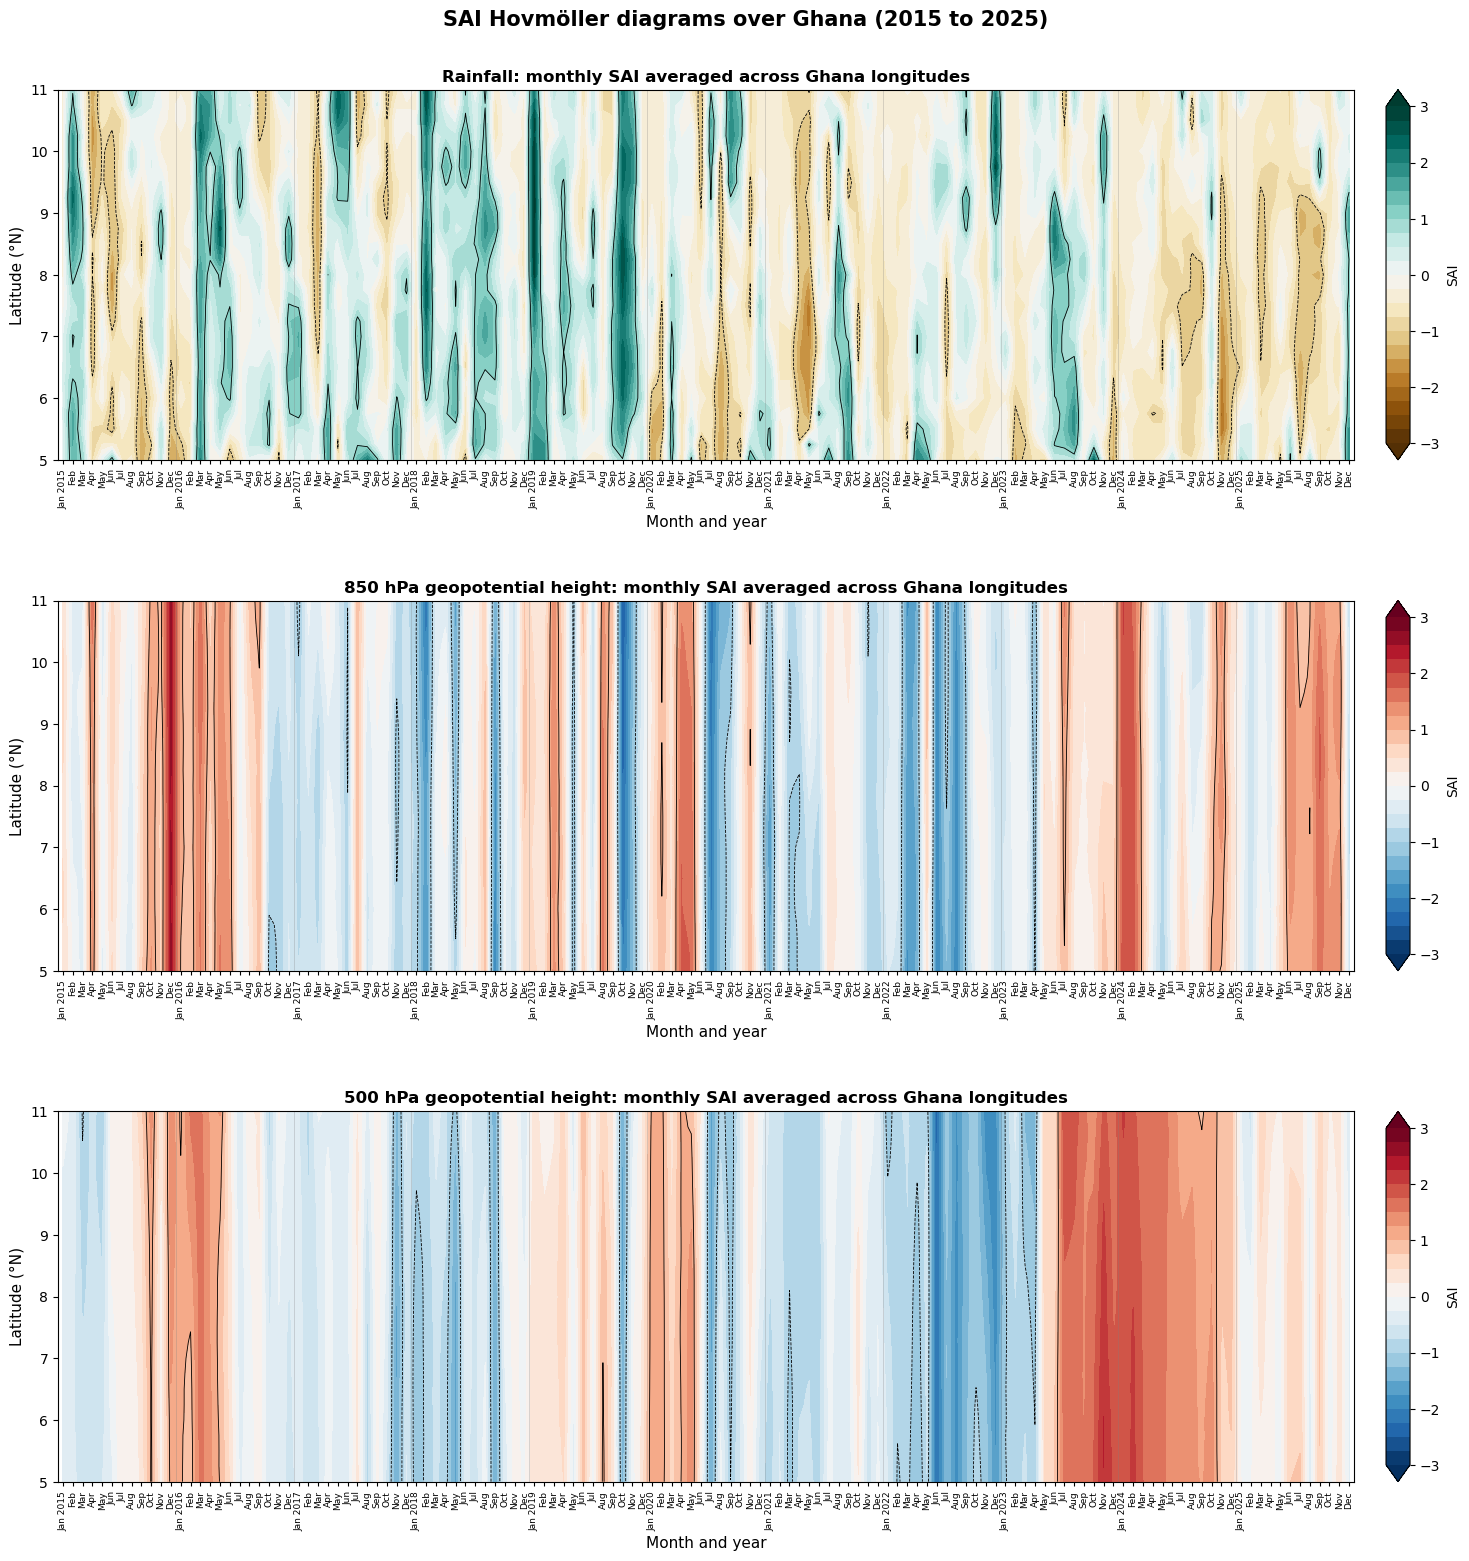

In [23]:
# =============================================================================
# 20B. FIGURE 06b: SAI HOVMOLLER DIAGRAMS (time 2015 to 2025 against latitude)
# =============================================================================
# SAI of every grid cell is averaged across longitude inside Ghana, then plotted
# for every month. This shows when, and at which latitudes, each variable was
# above normal (positive) or below normal (negative).
print("\nFIGURE 06b: SAI HOVMOLLER DIAGRAMS")
fig, axes = plt.subplots(3, 1, figsize=(16, 16), sharex=False)
fig.subplots_adjust(left=0.07, right=0.88, bottom=0.06, top=0.93, hspace=0.38)
sai_levels = np.linspace(-3, 3, 25)
for ax, key in zip(axes, FIELDS):
    h = prepare_hovmoller(sai[key])
    t_years = h.time.dt.year.values + (h.time.dt.month.values - 0.5) / 12.0
    cmap = SAI_RAIN_CMAP if key == "Rainfall" else SAI_Z_CMAP
    cf = ax.contourf(t_years, h.latitude.values, h.T.values, levels=sai_levels,
                     cmap=cmap, extend="both")
    ax.contour(t_years, h.latitude.values, h.T.values, levels=[-1, 1],
               colors="black", linewidths=0.6, linestyles=["--", "-"])
    # one tick for every month; January also shows the year
    month_ticks = [yr + (m - 0.5) / 12.0 for yr in range(START_YEAR, END_YEAR + 1)
                   for m in range(1, 13)]
    month_labels = [f"{MONTHS[m - 1]} {yr}" if m == 1 else MONTHS[m - 1]
                    for yr in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)]
    ax.set_xticks(month_ticks)
    ax.set_xticklabels(month_labels, rotation=90, fontsize=6.5, ha="center")
    ax.tick_params(axis="x", labelbottom=True, length=3)
    ax.set_xlim(START_YEAR, END_YEAR + 1)
    ax.set_xlabel("Month and year", fontsize=11)
    ax.set_ylabel("Latitude (\u00b0N)", fontsize=11)
    ax.yaxis.set_major_locator(MaxNLocator(6))
    ax.set_title(f"{META[key]['name']}: monthly SAI averaged across Ghana longitudes",
                 fontsize=12, fontweight="bold")
    for jan in range(START_YEAR, END_YEAR + 1):          # faint line at each January
        ax.axvline(jan, color="gray", linewidth=0.5, alpha=0.4)
    cax = fig.add_axes([0.90, ax.get_position().y0, 0.015, ax.get_position().height])
    cb = fig.colorbar(cf, cax=cax)
    cb.set_label("SAI", fontsize=10)
    cb.set_ticks([-3, -2, -1, 0, 1, 2, 3])
fig.suptitle(f"SAI Hovm\u00f6ller diagrams over Ghana ({START_YEAR} to {END_YEAR})",
             fontsize=15, fontweight="bold")
save(fig, "06b_hovmoller_SAI.png")



DRAWING RESULT TABLES


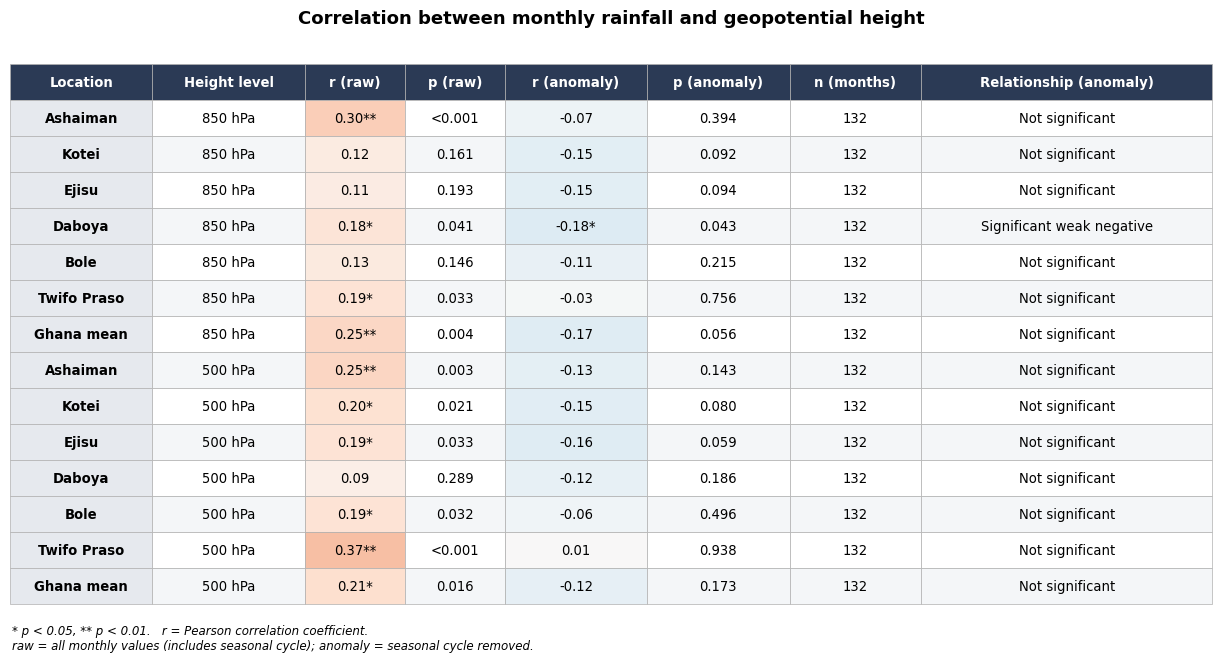

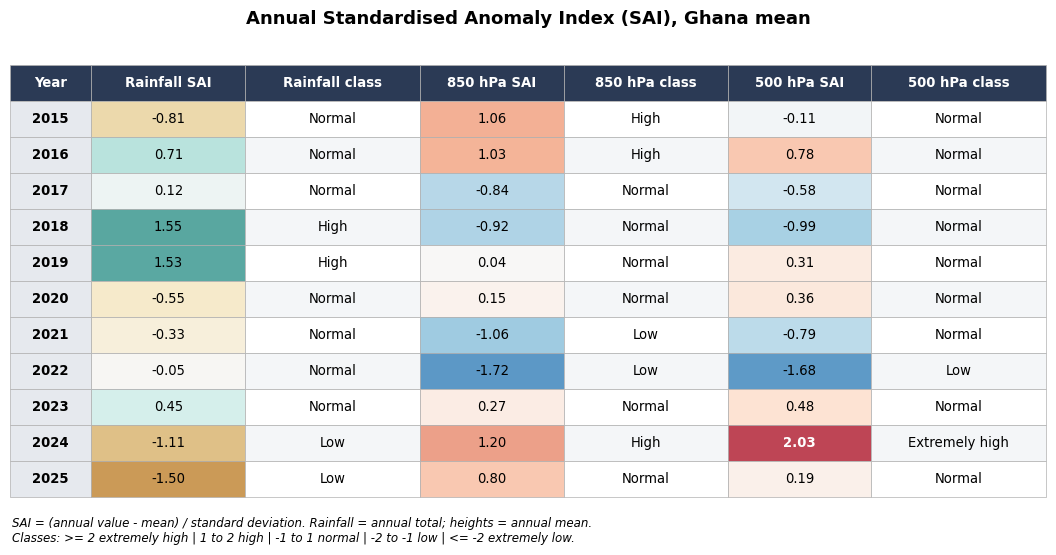

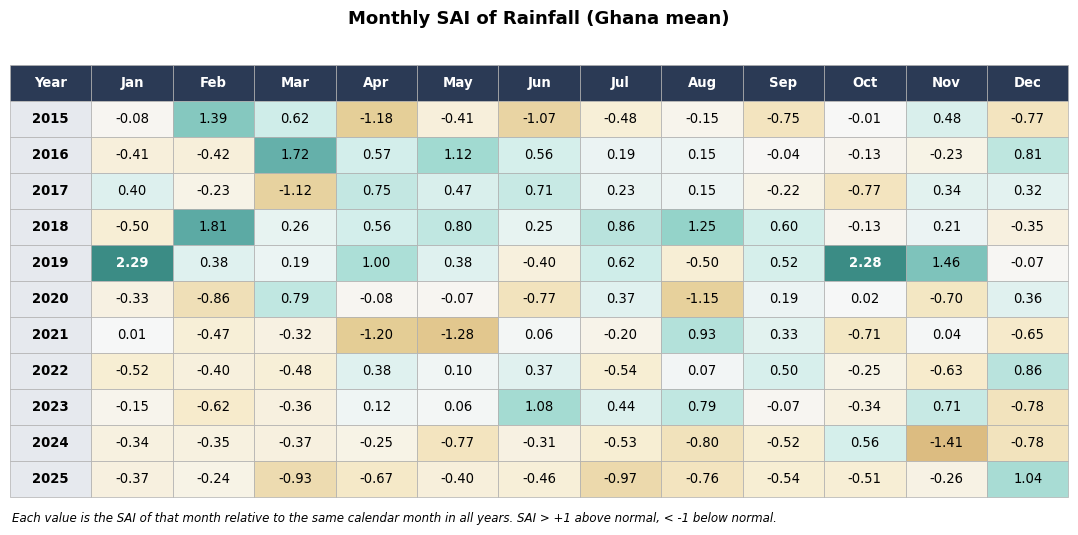

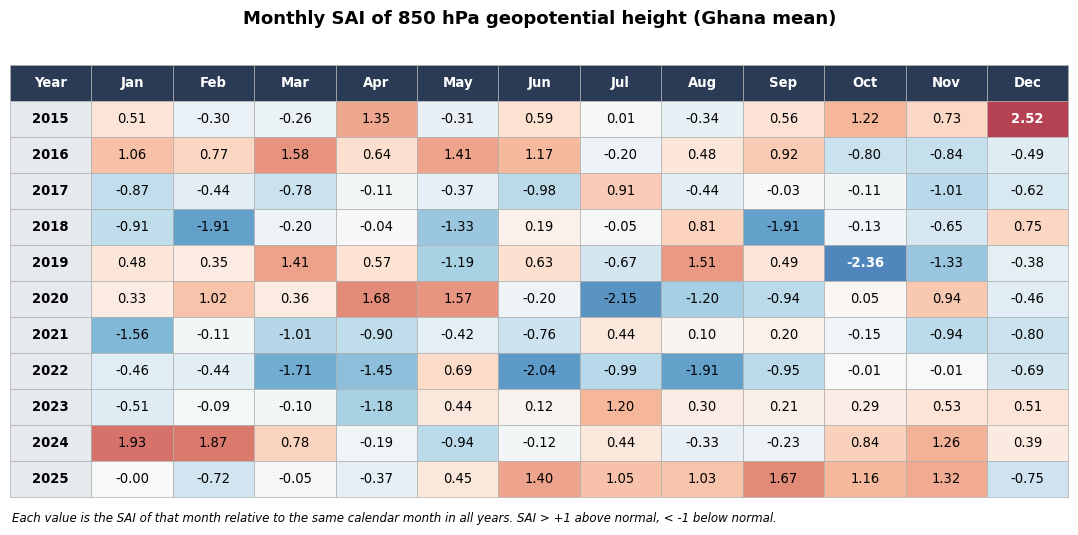

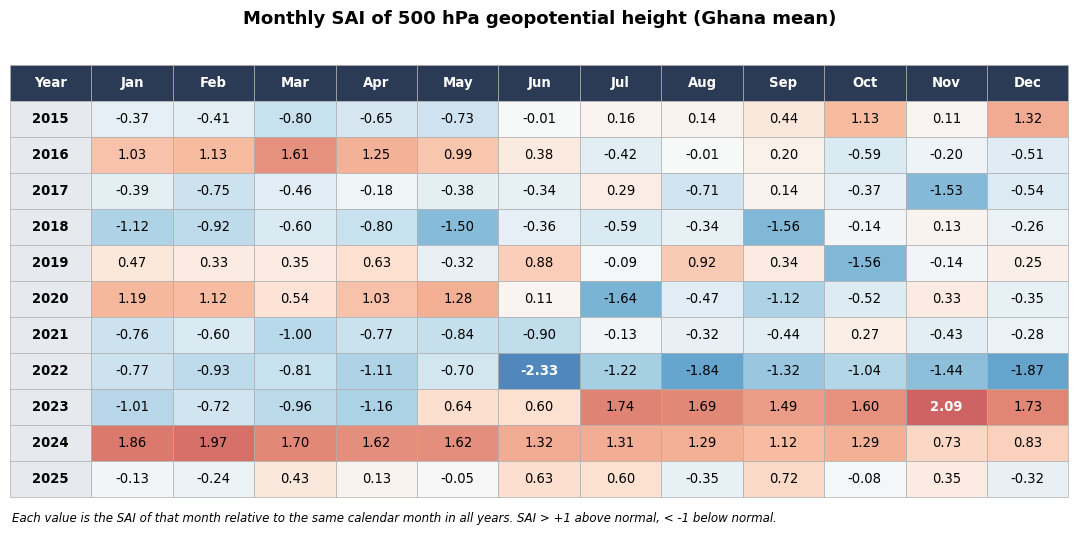

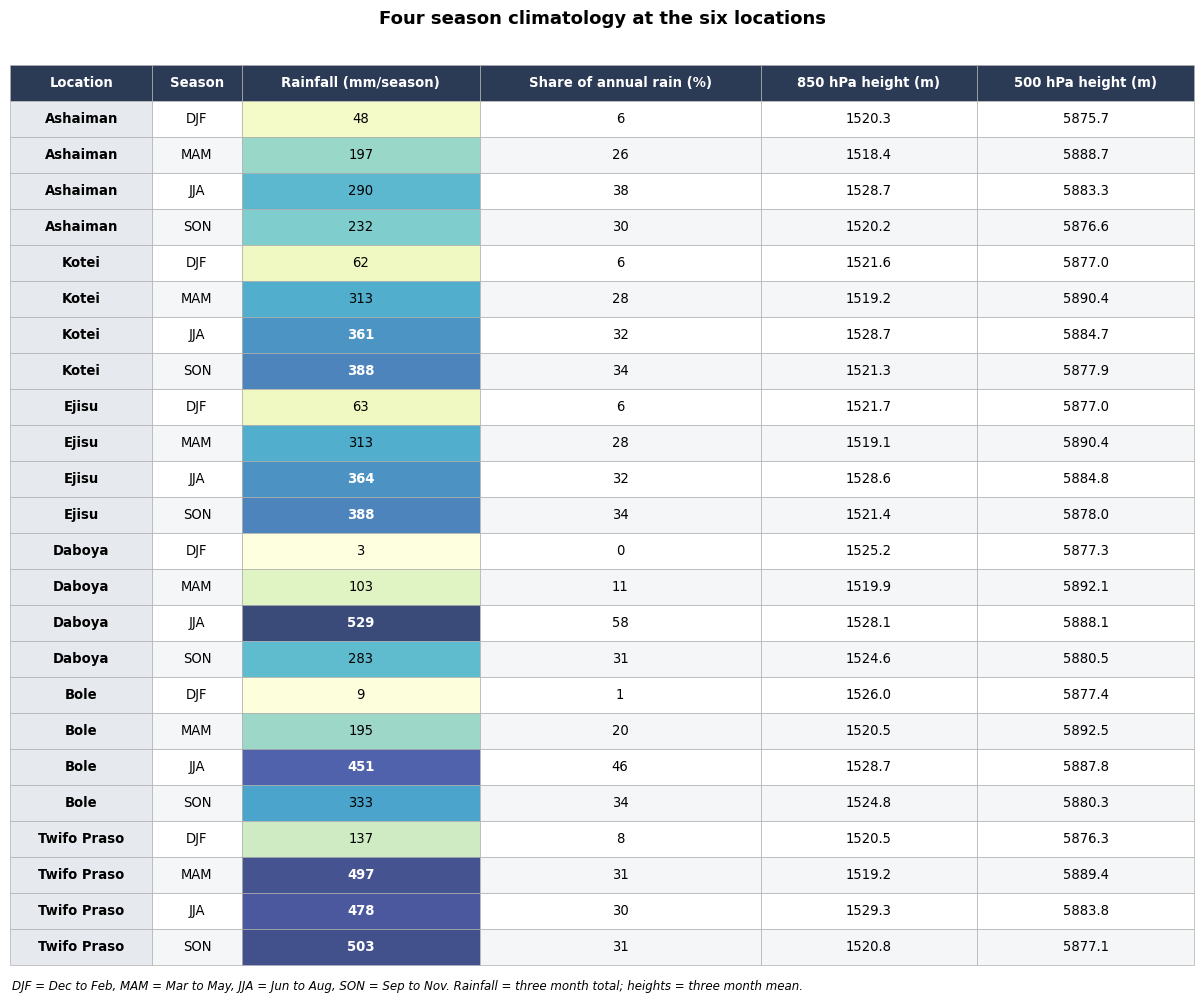

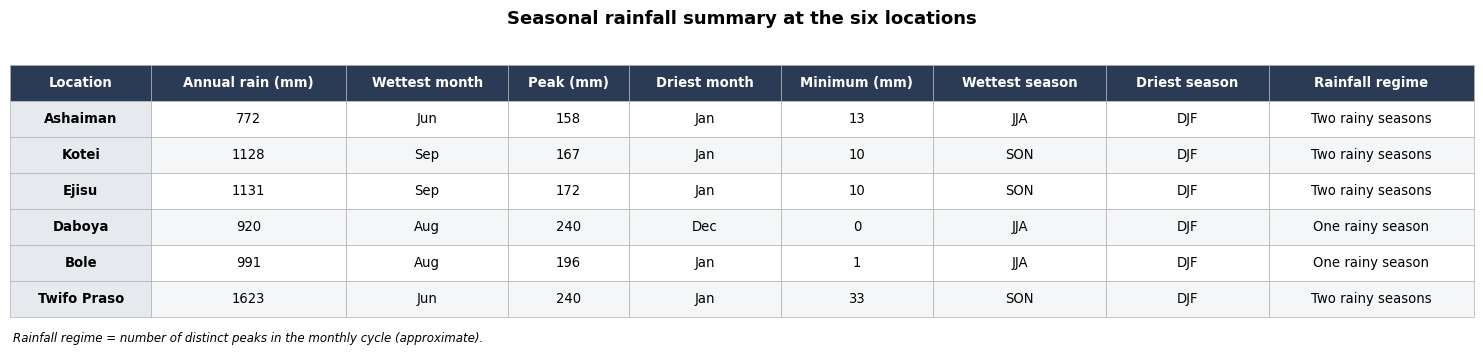


LINEAR TREND OF ANNUAL GHANA MEANS
                   Variable  Units per decade      r     p
                   Rainfall          -204.335 -0.445 0.170
850 hPa geopotential height            -0.011 -0.002 0.996
500 hPa geopotential height             3.524  0.217 0.522


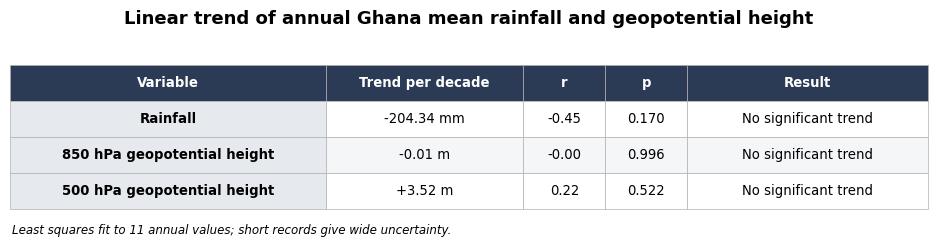

In [24]:
# =============================================================================
# 21. RESULT TABLES AS TABLE PICTURES (T01 ... T08)
# =============================================================================
print("\nDRAWING RESULT TABLES")


def p_text(p):
    if not np.isfinite(p):
        return "n/a"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def describe_r(r, p):
    if not np.isfinite(r):
        return "n/a"
    if p >= 0.05:
        return "Not significant"
    strength = "strong" if abs(r) >= 0.6 else "moderate" if abs(r) >= 0.3 else "weak"
    return f"Significant {strength} {'positive' if r > 0 else 'negative'}"


def sai_class(v):
    if not np.isfinite(v):
        return "n/a"
    if v >= 2:
        return "Extremely high"
    if v >= 1:
        return "High"
    if v > -1:
        return "Normal"
    if v > -2:
        return "Low"
    return "Extremely low"


SIG_NOTE = "* p < 0.05, ** p < 0.01.   r = Pearson correlation coefficient."

# ---- T01: correlation at the locations and Ghana mean -----------------------
cs = corr.copy()
cs["Site"] = pd.Categorical(cs["Site"], SITE_ORDER, ordered=True)
cs["Lv"] = pd.Categorical(cs["Level"], ["Z850", "Z500"], ordered=True)
cs = cs.sort_values(["Lv", "Site"]).reset_index(drop=True)
t1_text = pd.DataFrame({
    "Location": cs["Site"].astype(str),
    "Height level": cs["Level"].map(LEVEL_LABEL),
    "r (raw)": [f"{r:.2f}{star(p)}" if np.isfinite(r) else "n/a" for r, p in zip(cs.r_raw, cs.p_raw)],
    "p (raw)": [p_text(p) for p in cs.p_raw],
    "r (anomaly)": [f"{r:.2f}{star(p)}" if np.isfinite(r) else "n/a" for r, p in zip(cs.r_anom, cs.p_anom)],
    "p (anomaly)": [p_text(p) for p in cs.p_anom],
    "n (months)": cs["n"].astype(int),
    "Relationship (anomaly)": [describe_r(r, p) for r, p in zip(cs.r_anom, cs.p_anom)],
})
t1_val = pd.DataFrame(np.nan, index=t1_text.index, columns=t1_text.columns)
t1_val["r (raw)"] = cs["r_raw"].values
t1_val["r (anomaly)"] = cs["r_anom"].values
table_figure(
    t1_text, "T01_correlation_locations.png",
    "Correlation between monthly rainfall and geopotential height",
    val_df=t1_val, cmaps=[None, None, CORR_CMAP, None, CORR_CMAP, None, None, None],
    note=SIG_NOTE + "\nraw = all monthly values (includes seasonal cycle); "
                    "anomaly = seasonal cycle removed.")

# ---- T02: annual SAI, Ghana mean --------------------------------------------
rows_t = []
for yr, rw in ann_sai.iterrows():
    rows_t.append([str(yr),
                   f"{rw['Rainfall']:.2f}", sai_class(rw["Rainfall"]),
                   f"{rw['Z850']:.2f}", sai_class(rw["Z850"]),
                   f"{rw['Z500']:.2f}", sai_class(rw["Z500"])])
t2_text = pd.DataFrame(rows_t, columns=["Year", "Rainfall SAI", "Rainfall class",
                                        "850 hPa SAI", "850 hPa class",
                                        "500 hPa SAI", "500 hPa class"])
t2_val = pd.DataFrame(np.nan, index=t2_text.index, columns=t2_text.columns)
t2_val["Rainfall SAI"] = ann_sai["Rainfall"].values
t2_val["850 hPa SAI"] = ann_sai["Z850"].values
t2_val["500 hPa SAI"] = ann_sai["Z500"].values
table_figure(
    t2_text, "T02_annual_SAI_Ghana.png",
    "Annual Standardised Anomaly Index (SAI), Ghana mean",
    val_df=t2_val,
    cmaps=[None, SAI_RAIN_CMAP, None, SAI_Z_CMAP, None, SAI_Z_CMAP, None],
    ranges={1: (-2.5, 2.5), 3: (-2.5, 2.5), 5: (-2.5, 2.5)},
    note="SAI = (annual value - mean) / standard deviation. Rainfall = annual total; heights = annual mean.\n"
         "Classes: >= 2 extremely high | 1 to 2 high | -1 to 1 normal | -2 to -1 low | <= -2 extremely low.")

# ---- T03 to T05: monthly SAI (year x month), Ghana mean ------------------------
for key, fname in (("Rainfall", "T03_monthly_SAI_rainfall.png"),
                   ("Z850", "T04_monthly_SAI_850hPa.png"),
                   ("Z500", "T05_monthly_SAI_500hPa.png")):
    pv = sai_year_month(key)
    text_df = pd.DataFrame([[f"{v:.2f}" if np.isfinite(v) else "n/a" for v in row]
                            for row in pv.values], columns=pv.columns, index=pv.index)
    text_df = text_df.reset_index().rename(columns={"index": "Year"})
    text_df["Year"] = text_df["Year"].astype(str)
    val_df = pv.reset_index(drop=True).copy()
    val_df.insert(0, "Year", np.nan)
    table_figure(
        text_df, fname, f"Monthly SAI of {META[key]['name']} (Ghana mean)",
        val_df=val_df,
        cmaps=[None] + [SAI_RAIN_CMAP if key == "Rainfall" else SAI_Z_CMAP] * 12,
        ranges={c: (-3, 3) for c in range(1, 13)},
        note="Each value is the SAI of that month relative to the same calendar month in all years. "
             "SAI > +1 above normal, < -1 below normal.")

# ---- T06: four season climatology at the six locations ----------------------
t6_text = pd.DataFrame({
    "Location": seasonal_table["Site"],
    "Season": seasonal_table["Season"],
    "Rainfall (mm/season)": seasonal_table["Rainfall"].map(lambda v: f"{v:.0f}"),
    "Share of annual rain (%)": seasonal_table["Rain share (%)"].map(lambda v: f"{v:.0f}"),
    "850 hPa height (m)": seasonal_table["Z850"].map(lambda v: f"{v:.1f}"),
    "500 hPa height (m)": seasonal_table["Z500"].map(lambda v: f"{v:.1f}"),
})
t6_val = pd.DataFrame(np.nan, index=t6_text.index, columns=t6_text.columns)
t6_val["Rainfall (mm/season)"] = seasonal_table["Rainfall"].values
table_figure(
    t6_text, "T06_four_season_climatology.png",
    "Four season climatology at the six locations",
    val_df=t6_val, cmaps=[None, None, PRECIP_CMAP, None, None, None],
    ranges={2: (0, float(seasonal_table["Rainfall"].max()))},
    note="DJF = Dec to Feb, MAM = Mar to May, JJA = Jun to Aug, SON = Sep to Nov. "
         "Rainfall = three month total; heights = three month mean.")

# ---- T07: seasonal summary / rainfall regime --------------------------------
t7_text = pd.DataFrame({
    "Location": season_summary["Location"],
    "Annual rain (mm)": season_summary["Annual rainfall (mm)"].map(lambda v: f"{v:.0f}"),
    "Wettest month": season_summary["Wettest month"],
    "Peak (mm)": season_summary["Peak (mm/month)"].map(lambda v: f"{v:.0f}"),
    "Driest month": season_summary["Driest month"],
    "Minimum (mm)": season_summary["Minimum (mm/month)"].map(lambda v: f"{v:.0f}"),
    "Wettest season": season_summary["Wettest season"],
    "Driest season": season_summary["Driest season"],
    "Rainfall regime": season_summary["Rainfall regime"],
})
table_figure(
    t7_text, "T07_seasonal_summary.png",
    "Seasonal rainfall summary at the six locations",
    note="Rainfall regime = number of distinct peaks in the monthly cycle (approximate).")

# ---- T08: linear trend of the annual Ghana means ---------------------------
save_csv(trend_table.round(4), "annual_trends_Ghana.csv", index=False)
t8_text = pd.DataFrame({
    "Variable": trend_table["Variable"],
    "Trend per decade": [f"{v:+.2f} {'mm' if k == 'Rainfall' else 'm'}"
                         for k, v in zip(FIELDS, trend_table["Units per decade"])],
    "r": trend_table["r"].map(lambda v: f"{v:.2f}"),
    "p": trend_table["p"].map(p_text),
    "Result": [("Significant trend" if p < 0.05 else "No significant trend")
               for p in trend_table["p"]],
})
print("\nLINEAR TREND OF ANNUAL GHANA MEANS")
print(trend_table.round(3).to_string(index=False))
table_figure(
    t8_text, "T08_annual_trends.png",
    "Linear trend of annual Ghana mean rainfall and geopotential height",
    note=f"Least squares fit to {END_YEAR - START_YEAR + 1} annual values; "
         "short records give wide uncertainty.")


In [25]:
# =============================================================================
# 22. COMPLETION MESSAGE
# =============================================================================
print("\n" + "=" * 70)
print("MET 361 ANALYSIS COMPLETED")
print("=" * 70)
print(f"Study period: {START_YEAR} to {END_YEAR} | Months: {n_months} | Locations: {len(SITES)}")
print(f"\nFigures ({FIG_DIR}):")
for f in ("01_annual_spatial_maps", "02_seasonal_rainfall_maps",
          "02b_seasonal_850hPa_height_maps", "02c_seasonal_500hPa_height_maps",
          "03_seasonal_variation_six_locations", "04_correlation_bars",
          "05_SAI_annual_bars",
          "05b_SAI_monthly_bars", "06_hovmoller_climatology",
          "06b_hovmoller_SAI"):
    print(f"  {f}.png")
if not INCLUDE_MONTHLY_SAI_BARS:
    print("  (05b was skipped because INCLUDE_MONTHLY_SAI_BARS = False)")
print(f"\nTables ({TAB_DIR}):")
print("  T01 ... T08 (table pictures) and the CSV files")
print("=" * 70)



MET 361 ANALYSIS COMPLETED
Study period: 2015 to 2025 | Months: 132 | Locations: 6

Figures (outputs\figures):
  01_annual_spatial_maps.png
  02_seasonal_rainfall_maps.png
  02b_seasonal_850hPa_height_maps.png
  02c_seasonal_500hPa_height_maps.png
  03_seasonal_variation_six_locations.png
  04_correlation_bars.png
  05_SAI_annual_bars.png
  05b_SAI_monthly_bars.png
  06_hovmoller_climatology.png
  06b_hovmoller_SAI.png

Tables (outputs\tables):
  T01 ... T08 (table pictures) and the CSV files
